# Subtrace-Conditional Validation: Disentangling an Input-Model Error from a Logic Error (Bivariate Output)

This notebook implements the subtrace-conditional validation framework of
`NRL_Subtrace_V1.pdf` (Sections 2-3) on a controlled 3-station tandem queue
with **two independent, tunable, deliberate defects**:

1. an **input-model error** &mdash; Station 2's service-time distribution is
   misspecified (`BAD_S2_MEAN`, true `1.0` -> candidate `4.0`), and
2. a **logic error** &mdash; the candidate simulator's blocking mechanism
   assumes the **wrong buffer capacity** for Station 3
   (`CAND_B3_BUFFER`, true `BUFFERS[2]=5` -> candidate baseline `1`).

## Revision: the logic error is now a tunable buffer misspecification, not a
## separate algorithm

An earlier version of this notebook implemented the logic error as a
qualitatively different algorithm: the candidate simulator routed a
completed job into an unbounded "holding area" instead of blocking its
server when the downstream buffer was full. That made "how wrong is the
logic" an all-or-nothing switch with no way to dial its severity.

The mechanism has been replaced with something both simpler and tunable:
**the candidate's blocking logic is always the correct blocking-after-service
algorithm** (the same code path used to generate the true history); the only
way it can be wrong is if it is handed the **wrong buffer capacity**.
Concretely, `run_period` always blocks an upstream server when its
downstream buffer is full and unblocks it once space frees up &mdash; but
the true history is generated by passing it `BUFFERS=(2,5,5)`, while a
"logic error" candidate replication is generated by passing it
`CAND_BUFFERS=(2,5,CAND_B3_BUFFER)` instead. Setting `CAND_B3_BUFFER =
BUFFERS[2]` (`=5`) turns the logic error off entirely (Case 3/4 collapse
into Case 1/2); smaller values make the misspecification more severe. The
baseline used throughout this notebook is `CAND_B3_BUFFER = 1`, the smallest
possible value, chosen for a clean pedagogical signal exactly as
`BAD_S2_MEAN` was chosen for the input error (see the "Calibration" note
below). Station 3 was chosen because it is the tightest true buffer (`5`)
and, per the DES engine's blocking topology, the one whose downstream
capacity gates whether **Station 2** ever blocks.

## Revision: the two Rosenblatt coordinates are now tested jointly, not
## separately

An earlier version of this notebook computed the Rosenblatt PIT pair
`(U1_t, U2_t)` correctly (Section 3), but then tested `{U1_t}` and `{U2_t}`
**separately** against `Uniform(0,1)`, Holm-correcting a family of `2x15=30`
(configuration, output) hypotheses. `NRL_Subtrace_V1.pdf` Section 2.3 is
explicit that this is not sufficient: each Rosenblatt coordinate can be
marginally `Uniform(0,1)` even when the *dependence* between them is
misspecified, since the population guarantee is that the **pair**
`(U1,U2) ~ Uniform([0,1]^2)`, not that each coordinate is separately
uniform. This notebook now pools the **pairs** `{(U1_t,U2_t)}_{t=1}^T` and
tests them jointly against `Uniform([0,1]^2)` via the statistic
`W_A^{(2)}` of Section 2.3, computed numerically (Section 3 below has the
details, including why this uses an exact bipartite-matching solver rather
than a general-purpose optimal-transport routine). This is a single test per
configuration, so the Holm family shrinks to `m=15` (one hypothesis per
non-trivial configuration), not `30`.

## What the notebook still does, unchanged

- Two outputs: `Y1` = mean waiting time (min), `Y2` = fraction of arrivals
  balked at Station 1 during the period (its buffer, capacity `2`, is
  deliberately tight so balking is a well-populated continuous KPI rather
  than a near-zero indicator).
- One long `T=80`-period trajectory, hot-started `psi_t` re-initialization
  each period, `R=120` replications per period per configuration, all `2^4`
  subtrace configurations over the 4 input processes (Arrivals, S1, S2, S3).
- Trace-exhaustion handling (Section 1): once a station's historical
  service-time list for the current period is exhausted, further draws for
  that station fall back to a fresh candidate-model draw, logged as a
  diagnostic.
- Per-configuration null calibration (Section 3): each of the 16
  configurations is calibrated from *its own* Case-1 (fully correct)
  replicates, not a pooled or single-reference calibration, for the same
  KDE-bias reasons documented there.
- Section 7's design-of-experiments / bootstrap attribution, now run once
  (on the joint statistic) instead of once per output; Section 9's
  practical-significance layer (`NRL_Subtrace_V1.pdf` Section 2.7), applied
  per-output as before, is unaffected by the joint-test change since it
  never used `W_A` at all.

Every numeric claim made in the markdown cells below reflects the actual
executed output of this version of the notebook.

In [72]:
import copy
import heapq
import itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm, qmc, gaussian_kde
from scipy.optimize import linear_sum_assignment
from matplotlib.lines import Line2D
from sklearn.tree import DecisionTreeRegressor, plot_tree
import ot  # POT (Python Optimal Transport) -- only used when W_METHOD == "exact"

# --- Reproducibility: every random draw in this notebook is derived from SEED ---
# rng          : Section 2 (true-history generation) + Section 4 (main 16-config x4-case test,
#                including its LOO null-calibration Monte Carlo draws)
# rng_doe      : Section 7 (DoE bootstrap attribution) -- deliberately a SEPARATE generator from
#                `rng`, not a continuation of it, so Section 7 always reproduces the same result
#                regardless of exactly how Section 4 consumed `rng`'s stream.
# sklearn's DecisionTreeRegressor calls (Section 7) already pass random_state=SEED directly.
# `_sanity_check()`'s internal rng_local uses its own fixed literal seed (independent of SEED,
# by design -- it's a self-contained check, not part of the reported results).
#
# `rng`/`rng_doe` are ordinary mutable Generator objects created ONCE, here, at import time: full
# reproducibility requires Kernel -> Restart & Run All. Rerunning a single cell that consumes one
# of them a second time (without restarting) advances that generator further and WILL change that
# cell's results -- this is standard stateful-RNG behavior, not a bug.
SEED = 2026
rng = np.random.default_rng(SEED)
rng_doe = np.random.default_rng(SEED + 1)

# --- Wasserstein-2-to-uniform computation method ---
# "fast" (default): exact W_2 (squared-Euclidean-cost) distance between the pooled empirical
#     points and a FIXED, small (T-point) low-discrepancy reference, via bipartite matching
#     (Hungarian algorithm). This is exact for that specific empirical-vs-reference comparison,
#     but the T-point reference is itself only a coarse finite stand-in for the true continuous
#     Uniform([0,1]^2) target.
# "exact": exact W_2 distance between the pooled empirical points and a much denser
#     N_EXACT_REF-point reference, via POT's network-simplex optimal-transport solver
#     (ot.emd2), which (unlike scipy's bipartite matching) handles the resulting unequal point
#     counts. This converges to the true continuous-target distance as N_EXACT_REF grows, at
#     substantially higher per-call cost -- every W_A^(2) evaluation everywhere in the notebook
#     (main test, null calibration, bootstrap, DoE) uses this same setting.
W_METHOD = "fast"       # "fast" or "exact"
N_EXACT_REF = 2000      # reference sample size used only when W_METHOD == "exact"; larger = closer
                         # to the true continuous-uniform target, but roughly linearly slower per call

# --- system parameters ---
N_STATIONS = 3
# (B1, B2, B3), the TRUE buffer capacities. B1 is deliberately tight (2) so that
# balking at Station 1 -- the second output below -- happens often enough to be a
# useful continuous KPI; B3 stays tight (5) as the blocking hotspot the logic
# defect (below) misspecifies.
BUFFERS = (2, 5, 5)
PERIOD_LEN = 30.0                    # minutes per period
T_PERIODS = 80                       # number of historical periods (one long trajectory)
R_REPS = 120                         # simulation replications per period per configuration
ARRIVAL_RATE = 0.7                # per minute (stationary Poisson)
TRUE_SERVICE_MEANS = (1.0, 1.0, 2.0) # (S1, S2, S3) true means

# --- Deliberate, tunable defects for the candidate model ---
BAD_S2_MEAN = 4.0                    # input-model error: true=1.0; see "Calibration" note below.

CAND_B3_BUFFER = 1                   # logic error: candidate's (mis)assumed capacity for Station 3's
                                      # buffer; true value is BUFFERS[2] (=5). This is the tunable
                                      # "amount of logic misspecification" -- set CAND_B3_BUFFER =
                                      # BUFFERS[2] to turn the logic defect off, or any value in
                                      # {1,...,4} to dial its severity (1 = baseline, most severe).
CAND_BUFFERS = (BUFFERS[0], BUFFERS[1], CAND_B3_BUFFER)

PROCESS_NAMES = ['Arrivals', 'S1', 'S2', 'S3']


def balk_fraction(counts):
    '''counts = (n_arrivals, n_balks) from run_period. Returns 0.0 for a period
    with no arrivals at all (never observed in practice at this arrival rate,
    but guarded for safety).'''
    n_arrivals, n_balks = counts
    return n_balks / n_arrivals if n_arrivals else 0.0


print(f'T={T_PERIODS} periods x R={R_REPS} reps x 16 configs x 4 cases = '
      f'{T_PERIODS*R_REPS*16*4:,} single-period simulations, each producing a (wait, balk %) pair '
      f'(a full run takes a few minutes).')
print(f'Logic error: candidate assumes Station 3 buffer = {CAND_B3_BUFFER} (true = {BUFFERS[2]}).')

T=80 periods x R=120 reps x 16 configs x 4 cases = 614,400 single-period simulations, each producing a (wait, balk %) pair (a full run takes a few minutes).
Logic error: candidate assumes Station 3 buffer = 1 (true = 5).


## 1. Discrete-event simulation engine

State per station: `status` (`idle`/`busy`/`blocked`), `remaining` service
time if busy, and `w`, the job's **finalized prior waiting time** (queueing
time accumulated at earlier stations, excluding all service/blocking time).

Jobs waiting in a station's queue are stored as `[w, join_time]` pairs so
that the additional wait accrued while queueing can be added the moment
service starts. State is re-baselined to the period boundary whenever a
period ends, so the next period can hot-start cleanly from `psi_t`.

**The blocking mechanism is always the correct one**: if a job completes
service at Station `j` (`j=1,2`) and the downstream buffer is full, the job
stays at Station `j`'s server, and that server is blocked until the
downstream buffer frees a slot. There is no separate "wrong logic" code
path any more (see the revision note in `## 0` above) &mdash; a candidate
replication becomes logically wrong purely by being handed the wrong
`buffers` tuple, i.e. `CAND_BUFFERS` in place of the true `BUFFERS`. This is
implemented simply by threading `buffers` through every `can_accept()` call
in `run_period`; `CAND_BUFFERS` and `BUFFERS` only differ in Station 3's
slot, so Station 1's balking and Station 2's own buffer check are always
correct — only whether Station 2 gets blocked (which depends on Station 3's
*assumed* capacity) can be wrong.

Historical traces are replayed as indexed sequences, consumed one draw per
"start of service" event. If a station's per-period historical trace is
exhausted, further draws for that station fall back to a fresh sample from
the **candidate** service-time model, and the fallback is counted (see the
diagnostic in Section 4). This remains common whenever a station's trace is
fixed while an *upstream* process is left simulated, for the same reason as
before: a randomly-varying upstream job count naturally differs from the
historical count.

For the second output, the engine counts every arrival to Station 1 and how
many balk (buffer already at capacity `BUFFERS[0]=2` on arrival, so the job
leaves without entering): `Y_{t2} =` (balked arrivals) / (arrivals) during
the period.

In [73]:
def new_state():
    return {
        'server': [{'status': 'idle', 'remaining': None, 'w': None} for _ in range(N_STATIONS)],
        'depart_time': [None, None, None],
        'queue': [[] for _ in range(N_STATIONS)],   # list of [w, join_time]
    }


def restart_busy_events(state, period_len):
    '''Populate depart_time (relative to the new period's start) for any
    station left busy at the end of the previous period, from its saved
    `remaining` service time.'''
    for j in range(N_STATIONS):
        srv = state['server'][j]
        if srv['status'] == 'busy':
            state['depart_time'][j] = srv['remaining']
    return state


def can_accept(state, k, buffers):
    srv = state['server'][k]
    if srv['status'] == 'idle' and len(state['queue'][k]) == 0:
        return True
    return len(state['queue'][k]) < buffers[k]

In [74]:
def make_service_drawer(mode, hist_list, cand_mean, rng, fallback_counter, key):
    '''mode='replay': consume hist_list in order, falling back to a fresh
    candidate-model draw (and incrementing fallback_counter[key]) once
    exhausted. mode='draw': always draw fresh from the candidate model.
    Returns (draw_fn, consumed_list) where consumed_list records every value
    actually used (needed to save the trace when generating the TRUE history).'''
    consumed = []
    idx = [0]

    def draw():
        if mode == 'replay':
            if idx[0] < len(hist_list):
                v = hist_list[idx[0]]
                idx[0] += 1
            else:
                v = rng.exponential(cand_mean)
                fallback_counter[key] += 1
        else:
            v = rng.exponential(cand_mean)
        consumed.append(v)
        return v

    return draw, consumed


def run_period(state0, period_len, buffers,
               arrival_mode, arrival_rate, arrival_hist,
               service_modes, service_means, service_hist,
               rng, fallback_counts):
    '''Simulate one period of length `period_len`, hot-started from state0
    (already deep-copied and passed through restart_busy_events by the
    caller). Returns (end_state, departures, (n_arrivals, n_balks), consumed).

    The blocking-after-service mechanism is always the correct one; the only
    way a replication can be logically wrong is if `buffers` differs from
    the true system's capacities (see CAND_BUFFERS, Section 0/1 above).

    arrival_mode / service_modes[j]: 'draw' (fresh from the candidate model)
    or 'replay' (consume the given historical per-period trace).'''
    state = state0
    heap = []
    counter = itertools.count()
    departures = []
    n_arrivals = 0
    n_balks = 0

    drawers, consumed_service = [], []
    for j in range(N_STATIONS):
        d, c = make_service_drawer(service_modes[j], service_hist[j], service_means[j],
                                    rng, fallback_counts, f'S{j+1}')
        drawers.append(d)
        consumed_service.append(c)

    def draw_service(j):
        return drawers[j]()

    if arrival_mode == 'replay':
        arrival_epochs = list(arrival_hist)
    else:
        arrival_epochs = []
        t = 0.0
        while True:
            t += rng.exponential(1.0 / arrival_rate)
            if t >= period_len:
                break
            arrival_epochs.append(t)
    consumed_arrivals = list(arrival_epochs)

    for a in arrival_epochs:
        heapq.heappush(heap, (a, next(counter), 'arrival', None))
    for j in range(N_STATIONS):
        if state['server'][j]['status'] == 'busy':
            heapq.heappush(heap, (state['depart_time'][j], next(counter), 'depart', j))

    def start_service(j, w, now):
        stime = draw_service(j)
        state['server'][j] = {'status': 'busy', 'remaining': stime, 'w': w}
        state['depart_time'][j] = now + stime
        heapq.heappush(heap, (now + stime, next(counter), 'depart', j))

    def admit(k, w, now):
        srv = state['server'][k]
        if srv['status'] == 'idle' and len(state['queue'][k]) == 0:
            start_service(k, w, now)
        else:
            state['queue'][k].append([w, now])

    def pull_queue(j, now):
        q = state['queue'][j]
        if state['server'][j]['status'] == 'idle' and q:
            w, join_time = q.pop(0)
            start_service(j, w + (now - join_time), now)

    def settle(now):
        changed = True
        while changed:
            changed = False
            for junc in range(2):
                up, down = junc, junc + 1
                srv = state['server'][up]
                if srv['status'] == 'blocked' and can_accept(state, down, buffers):
                    admit(down, srv['w'], now)
                    state['server'][up] = {'status': 'idle', 'remaining': None, 'w': None}
                    state['depart_time'][up] = None
                    pull_queue(up, now)
                    changed = True

    while heap:
        now, _, etype, payload = heapq.heappop(heap)
        if now > period_len:
            break  # remaining heap entries (all later) are recovered from depart_time at snapshot time
        if etype == 'arrival':
            n_arrivals += 1
            if can_accept(state, 0, buffers):
                admit(0, 0.0, now)
            else:
                n_balks += 1
            settle(now)
        else:
            j = payload
            srv = state['server'][j]
            w = srv['w']
            if j < N_STATIONS - 1:
                down = j + 1
                if can_accept(state, down, buffers):
                    admit(down, w, now)
                    state['server'][j] = {'status': 'idle', 'remaining': None, 'w': None}
                    state['depart_time'][j] = None
                    pull_queue(j, now)
                else:
                    state['server'][j] = {'status': 'blocked', 'remaining': 0.0, 'w': w}
                    state['depart_time'][j] = None
            else:
                departures.append(w)
                state['server'][j] = {'status': 'idle', 'remaining': None, 'w': None}
                state['depart_time'][j] = None
                pull_queue(j, now)
            settle(now)

    end_state = new_state()
    for j in range(N_STATIONS):
        srv = state['server'][j]
        if srv['status'] == 'busy':
            end_state['server'][j] = {'status': 'busy', 'remaining': state['depart_time'][j] - period_len, 'w': srv['w']}
        elif srv['status'] == 'blocked':
            end_state['server'][j] = {'status': 'blocked', 'remaining': 0.0, 'w': srv['w']}
        else:
            end_state['server'][j] = {'status': 'idle', 'remaining': None, 'w': None}
        end_state['queue'][j] = [[w + (period_len - jt), 0.0] for (w, jt) in state['queue'][j]]

    consumed = {'arrival': consumed_arrivals, 'service': consumed_service}
    return end_state, departures, (n_arrivals, n_balks), consumed

### Sanity checks

Before trusting any statistical result, we verify the two properties the
paper's theory guarantees, now checked for **both** outputs (waiting time
and balk %):

1. Replaying the **full historical trace** with the **true buffer
   capacities** must reproduce both recorded outputs *exactly* (Section 2.4:
   `y_t = H(psi_t,xi_t)` when `H=H*` and there is no measurement noise).
2. Replaying the full trace with a **misspecified Station-3 buffer** must
   generally *differ* from the true outputs, in periods where the smaller
   buffer would actually have changed blocking behavior.

In [75]:
def _sanity_check():
    buffers = (10, 15, 15)
    rng_local = np.random.default_rng(7)
    T, period_len = 20, 30.0
    arr_rate, true_means = 0.45, (1.0, 1.0, 2.0)

    psi_list, arrival_hist = [], []
    service_hist = [[] for _ in range(3)]
    y0_1, y0_2 = [], []
    state = new_state()
    for t in range(T):
        psi_list.append(copy.deepcopy(state))
        state_in = restart_busy_events(copy.deepcopy(state), period_len)
        fb = {'S1': 0, 'S2': 0, 'S3': 0}
        new_st, deps, counts, consumed = run_period(state_in, period_len, buffers, 'draw', arr_rate, None,
                                                     ['draw'] * 3, true_means, (None, None, None), rng_local, fb)
        arrival_hist.append(consumed['arrival'])
        for j in range(3):
            service_hist[j].append(consumed['service'][j])
        y0_1.append(np.mean(deps) if deps else 0.0)  # consistent with the candidate side's zero-departure convention
        y0_2.append(balk_fraction(counts))
        state = new_st
    y0_1, y0_2 = np.array(y0_1), np.array(y0_2)

    def replay(buffers_used):
        out1, out2 = [], []
        for t in range(T):
            fb = {'S1': 0, 'S2': 0, 'S3': 0}
            st0 = restart_busy_events(copy.deepcopy(psi_list[t]), period_len)
            _, deps, counts, _ = run_period(st0, period_len, buffers_used, 'replay', arr_rate, arrival_hist[t],
                                             ['replay'] * 3, true_means,
                                             [service_hist[j][t] for j in range(3)], rng_local, fb)
            out1.append(np.mean(deps) if deps else 0.0)
            out2.append(balk_fraction(counts))
        return np.array(out1), np.array(out2)

    recon1_true, recon2_true = replay(buffers)
    recon1_wrong, recon2_wrong = replay((buffers[0], buffers[1], CAND_B3_BUFFER))
    max_diff1 = np.nanmax(np.abs(y0_1 - recon1_true))
    max_diff2 = np.nanmax(np.abs(y0_2 - recon2_true))
    n_diff_wrong = np.sum((np.abs(y0_1 - recon1_wrong) > 1e-9) | (np.abs(y0_2 - recon2_wrong) > 1e-9))
    assert max_diff1 < 1e-9, f'FAILED: full-trace + true buffer should reproduce wait exactly (max diff {max_diff1})'
    assert max_diff2 < 1e-9, f'FAILED: full-trace + true buffer should reproduce balk % exactly (max diff {max_diff2})'
    print(f'PASS: full-trace replay with the TRUE buffer reproduces both y0_1 (wait) and y0_2 (balk %) exactly '
          f'(max abs diff = {max_diff1:.2e}, {max_diff2:.2e}).')
    print(f'PASS: full-trace replay with a MISSPECIFIED Station-3 buffer (B3={CAND_B3_BUFFER} instead of '
          f'{buffers[2]}) differs from at least one true output in {n_diff_wrong}/{T} periods '
          f'(the periods where the smaller buffer would have changed blocking behavior).')

_sanity_check()

PASS: full-trace replay with the TRUE buffer reproduces both y0_1 (wait) and y0_2 (balk %) exactly (max abs diff = 0.00e+00, 0.00e+00).
PASS: full-trace replay with a MISSPECIFIED Station-3 buffer (B3=1 instead of 15) differs from at least one true output in 19/20 periods (the periods where the smaller buffer would have changed blocking behavior).


## 2. Generating the historical (true) trajectory

We simulate **one** long trajectory of $T=80$ periods (30 minutes each)
under the true logic and true input models, recording at each period the
hot-start state $\psi_t$, the realized subtraces $\xi_t$ (arrival epochs and
per-station service times, in the order consumed), and the noise-free
**pair** of outputs $\mathbf{y}_t^{(0)}=(y_{t1}^{(0)},y_{t2}^{(0)})$ (mean
waiting time, balk %). This is the only place the *true* system is ever
simulated; all candidate-model runs below hot-start from these same
$\psi_t$'s and reuse these same traces wherever a process is held fixed.

Y1 (wait):   mean=19.14 min, std=8.51 min, range=[2.03, 44.54]
Y2 (balk %): mean=26.5%, std=18.6%, range=[0.0%, 66.7%], fraction of periods with any balking=0.89
corr(Y1, Y2) = 0.545  (dependent but not redundant, as intended)


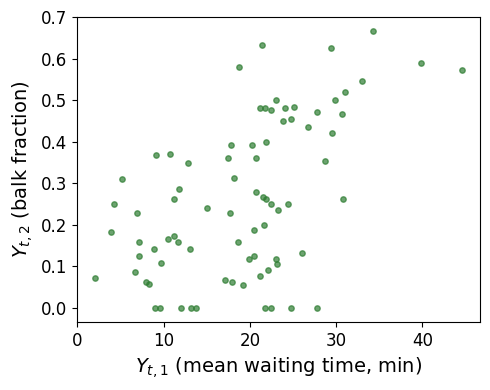

In [76]:
def generate_true_history(T, period_len, buffers, arr_rate, true_means, rng):
    psi_list, arrival_hist = [], []
    service_hist = [[] for _ in range(3)]
    y0_1, y0_2 = [], []
    state = new_state()
    for t in range(T):
        psi_list.append(copy.deepcopy(state))  # snapshot BEFORE this period, i.e. psi_t
        state_in = restart_busy_events(copy.deepcopy(state), period_len)
        fb = {'S1': 0, 'S2': 0, 'S3': 0}
        new_st, deps, counts, consumed = run_period(state_in, period_len, buffers, 'draw', arr_rate, None,
                                                     ['draw'] * 3, true_means, (None, None, None), rng, fb)
        arrival_hist.append(consumed['arrival'])
        for j in range(3):
            service_hist[j].append(consumed['service'][j])
        y0_1.append(np.mean(deps) if deps else 0.0)  # consistent with the candidate side's zero-departure convention
        y0_2.append(balk_fraction(counts))
        state = new_st
    return psi_list, arrival_hist, service_hist, np.array(y0_1), np.array(y0_2)


psi_list, arrival_hist, service_hist, y0_1, y0_2 = generate_true_history(
    T_PERIODS, PERIOD_LEN, BUFFERS, ARRIVAL_RATE, TRUE_SERVICE_MEANS, rng)
y_obs1 = y0_1
y_obs2 = y0_2

print(f'Y1 (wait):   mean={np.nanmean(y0_1):.2f} min, std={np.nanstd(y0_1):.2f} min, '
      f'range=[{np.nanmin(y0_1):.2f}, {np.nanmax(y0_1):.2f}]')
print(f'Y2 (balk %): mean={100*np.nanmean(y0_2):.1f}%, std={100*np.nanstd(y0_2):.1f}%, '
      f'range=[{100*np.nanmin(y0_2):.1f}%, {100*np.nanmax(y0_2):.1f}%], '
      f'fraction of periods with any balking={np.mean(y0_2 > 0):.2f}')
print(f'corr(Y1, Y2) = {np.corrcoef(y0_1, y0_2)[0, 1]:.3f}  (dependent but not redundant, as intended)')

fig, ax = plt.subplots(figsize=(5, 4))
ax.scatter(y0_1, y0_2, s=15, alpha=0.7, color='#2e7d32')
ax.set_xlabel('$Y_{t,1}$ (mean waiting time, min)', fontsize=14)
ax.set_ylabel('$Y_{t,2}$ (balk fraction)', fontsize=14)
ax.tick_params(axis='both', labelsize=12)
plt.tight_layout()
fig.savefig("Figures/tandem_true_history.png", dpi=200, bbox_inches="tight")
plt.show()



## 3. Candidate replication and the joint bivariate subtrace-conditional PIT

For a subtrace configuration `bits = (a, s1, s2, s3)` (`1` = historical/fixed,
`0` = simulated, matching `z_{s,A}`), we hot-start `R` replications from each
`psi_t` and run the candidate model, giving `R` paired replicates
`{(Y1_{t,A}^r, Y2_{t,A}^r)}_{r=1}^R`. From these we build a
**Gaussian-product-kernel bivariate KDE** and read off the two Rosenblatt
coordinates in closed form (no numerical integration): with per-dimension
Silverman bandwidths `h1, h2`,

```
U1_{t,A} = F_{t,A,1|2}(y_t1 | y_t2) = sum_r w_r(y_t2) * Phi((y_t1 - Y1_{t,A}^r)/h1)
```

and symmetrically for `U2_{t,A}` (this closed form follows because a
Gaussian-kernel bivariate KDE has Gaussian marginals/conditionals, so the
weights `w_r` are exactly Nadaraya-Watson kernel-regression weights).

### The test is now joint, not two separate marginal tests

Population guarantee (`NRL_Subtrace_V1.pdf` Sec 2.3): under correct
specification, `(U1_{t,A}, U2_{t,A}) ~ Uniform([0,1]^2)` **jointly**. Testing
`{U1_t}` and `{U2_t}` separately against `Uniform(0,1)` (an earlier version
of this notebook) only checks the two marginals, and can miss a pure
dependence-structure misspecification. We now pool the **pairs**
`{(U1_t,A, U2_t,A)}_{t=1}^T` and compute

```
W_A^(2) = W_2( (1/T) sum_t delta_{(U1_t,A,U2_t,A)},  Uniform([0,1]^2) ),
```

numerically (no closed form in 2D, unlike the scalar case).

**Why a bipartite matching, not a general OT solver.** Since the pooled
empirical sample and a same-size reference sample both carry uniform mass
`1/T`, the optimal transport plan between them is an exact **bipartite
matching**: solvable via the Hungarian algorithm
(`scipy.optimize.linear_sum_assignment`) on the `TxT` squared-Euclidean cost
matrix, then `sqrt(mean matched cost)`. This was verified directly to be
essential, not a micro-optimization: `scipy.stats.wasserstein_distance_nd`
(a general-purpose network-simplex OT solver) takes **>0.5s per call** at
`T=80`, while the matching-based estimator takes **~0.0002s per call** —
over 1000x faster. The null calibration below needs `N_MC=2000` evaluations
*per configuration* (16 configurations), i.e. 32,000 evaluations total; at
the general-solver's rate that is unusable (~5 hours), while the
matching-based estimator finishes in seconds.

**Fixed low-discrepancy reference, not a fresh random draw.** The reference
sample is a **fixed** (computed once, not redrawn per call) low-discrepancy
Halton sequence of `T` points in `[0,1]^2` (`JOINT_REF` below) — the 2D
analogue of the deterministic grid `(2t-1)/(2T)` used as the `Uniform(0,1)`
reference in the scalar case. A fresh random reference sample every call
would add avoidable Monte Carlo noise to the statistic and its null.

### Null calibration — unchanged in spirit, adapted to be joint

As before, evaluating the KDE-based conditional CDF at an external point is
biased toward 0.5 relative to the ideal `Uniform(0,1)`, so the null is
calibrated via **leave-one-out (LOO)** resampling of a *known-correctly-
specified* model's own replicates, **per configuration** (not pooled across
configurations or from a single reference configuration — see the discussion
in Section 8 for why that failed). The only change from before: the LOO
pair `(u1_loo[r], u2_loo[r])` for a given replicate `r` **must be kept
paired** when building each Monte Carlo null draw (never let `U1`'s
replicate index differ from `U2`'s), since mixing them would destroy exactly
the dependence structure the joint test is trying to check.

In [77]:
def _safe_normalize(w):
    '''Normalize a 1D weight vector, falling back to uniform weights if all
    kernel weights underflow to (numerically) zero -- this happens rarely,
    almost always in a bootstrap resample that by chance concentrates on a
    near-constant set of replicate values, driving the bandwidth to its
    floor and every kernel evaluation to exactly 0.0. Without this guard the
    normalization is a silent 0/0 = NaN that only surfaces much later
    (e.g. inside sklearn's tree.fit).'''
    s = w.sum()
    if not np.isfinite(s) or s <= 0:
        return np.full_like(w, 1.0 / len(w))
    return w / s


def _safe_normalize_rows(W):
    '''Row-wise analogue of _safe_normalize for the vectorized LOO estimator.'''
    s = W.sum(axis=1, keepdims=True)
    bad = ~np.isfinite(s) | (s <= 0)
    s_safe = np.where(bad, 1.0, s)
    Wn = W / s_safe
    if bad.any():
        Wn[bad.ravel()] = 1.0 / W.shape[1]
    return Wn


def _fit_bivariate_kde(reps1, reps2):
    '''Fit a genuine bivariate KDE (scipy.stats.gaussian_kde, Silverman bandwidth) to the R
    paired replicates and return its fitted 2x2 kernel covariance matrix H. gaussian_kde's
    multivariate Silverman/Scott rule scales the FULL sample covariance of (reps1, reps2)
    (including the cross term), unlike the old per-axis h1,h2 product kernel, which implicitly
    assumed the two outputs were independent when smoothing. Every mixture component shares this
    same H, so the mixture's marginal/conditional distributions are still exactly Gaussian --
    closed form, no numerical integration needed. Falls back to a tiny isotropic covariance
    (matching the old 1e-6 bandwidth floor) if the replicate sample is numerically degenerate
    (e.g. a deterministic full-trace replay), since gaussian_kde cannot fit a singular
    covariance matrix.'''
    try:
        kde = gaussian_kde(np.vstack([reps1, reps2]), bw_method="silverman")
        H = kde.covariance
        if not np.all(np.isfinite(H)) or H[0, 0] <= 0 or H[1, 1] <= 0:
            raise np.linalg.LinAlgError("degenerate covariance")
    except np.linalg.LinAlgError:
        H = np.diag([1e-12, 1e-12])
    return H


def bivariate_conditional_pit(reps1, reps2, y1, y2):
    '''Rosenblatt transform (NRL_main.tex's definition, fixed ordering (Y1, Y2)) via a genuine
    bivariate KDE. U1 is the MARGINAL cdf of Y1 (unconditional on Y2); U2 is the cdf of Y2
    CONDITIONAL on the realized Y1=y1. This -- not two symmetric conditional-on-each-other
    coordinates -- is what gives (U1, U2) the joint-uniformity guarantee under correct
    specification. Both are closed form since the KDE is a mixture of bivariate Gaussians
    sharing one covariance matrix H, whose marginal/conditional are themselves exactly Gaussian.'''
    H = _fit_bivariate_kde(reps1, reps2)
    H11, H12, H22 = H[0, 0], H[0, 1], H[1, 1]
    h1 = np.sqrt(H11)

    U1 = np.mean(norm.cdf((y1 - reps1) / h1))

    cond_var = max(H22 - H12 ** 2 / H11, 1e-12)
    cond_std = np.sqrt(cond_var)
    cond_means = reps2 + (H12 / H11) * (y1 - reps1)
    w1 = _safe_normalize(norm.pdf((y1 - reps1) / h1))
    U2 = np.sum(w1 * norm.cdf((y2 - cond_means) / cond_std))
    return U1, U2


def loo_conditional_pit(reps1, reps2):
    '''Vectorized leave-one-out version of the same (now genuinely-Rosenblatt) estimator, used
    only to calibrate the null distribution: for each replicate r, treat it as the "observation"
    and use the other R-1 replicates as the KDE basis. u1_loo[r] is the LOO MARGINAL cdf of Y1;
    u2_loo[r] is the LOO cdf of Y2 conditional on Y1=reps1[r]. The two returned arrays are PAIRED
    by r, which the joint null below relies on.'''
    H = _fit_bivariate_kde(reps1, reps2)
    H11, H12, H22 = H[0, 0], H[0, 1], H[1, 1]
    h1 = np.sqrt(H11)
    cond_var = max(H22 - H12 ** 2 / H11, 1e-12)
    cond_std = np.sqrt(cond_var)

    C1 = norm.cdf((reps1[:, None] - reps1[None, :]) / h1)
    np.fill_diagonal(C1, np.nan)
    u1_loo = np.nanmean(C1, axis=1)

    W1 = norm.pdf((reps1[:, None] - reps1[None, :]) / h1)
    np.fill_diagonal(W1, 0.0)
    W1 = _safe_normalize_rows(W1)
    cond_means = reps2[None, :] + (H12 / H11) * (reps1[:, None] - reps1[None, :])
    C2 = norm.cdf((reps2[:, None] - cond_means) / cond_std)
    u2_loo = np.sum(W1 * C2, axis=1)
    return u1_loo, u2_loo


# --- Joint bivariate discrepancy statistic (NRL_Subtrace_V1.pdf Sec 2.3) ---
JOINT_REF = qmc.Halton(d=2, seed=SEED).random(T_PERIODS)
EXACT_REF = qmc.Halton(d=2, seed=SEED + 1).random(N_EXACT_REF)


def wasserstein2_joint(U, ref=None):
    '''U: (T,2) pooled bivariate PIT pairs. W_METHOD="fast" (module-level switch, Cell 1):
    exact W_2 (squared-Euclidean-cost) distance to the fixed T-point reference via bipartite
    matching (Hungarian algorithm) -- exact for that specific T-vs-T comparison, but the T-point
    reference is itself only a finite approximation of the true continuous Uniform([0,1]^2)
    target. W_METHOD="exact": exact W_2 distance to the much denser N_EXACT_REF-point EXACT_REF
    via POT's network-simplex OT solver (ot.emd2), which handles the resulting unequal point
    counts and converges to the true continuous-target distance as N_EXACT_REF grows, at
    substantially higher per-call cost.'''
    if W_METHOD == "exact":
        a = np.full(U.shape[0], 1.0 / U.shape[0])
        b = np.full(EXACT_REF.shape[0], 1.0 / EXACT_REF.shape[0])
        M = np.sum((U[:, None, :] - EXACT_REF[None, :, :]) ** 2, axis=2)
        return np.sqrt(ot.emd2(a, b, M))
    ref_pts = JOINT_REF if ref is None else ref
    cost = np.sum((U[:, None, :] - ref_pts[None, :, :]) ** 2, axis=2)
    row_idx, col_idx = linear_sum_assignment(cost)
    return np.sqrt(cost[row_idx, col_idx].mean())


def calibrated_null_W_joint(pool, n_mc, T, rng):
    '''Monte-Carlo null distribution of the pooled JOINT statistic: draw T
    "periods" (with replacement) from the calibration pool, and for each, one
    of its R leave-one-out PIT PAIRS (same replicate r for both coordinates).'''
    n_rows, R, _ = pool.shape
    Ws = np.empty(n_mc)
    for i in range(n_mc):
        row_idx = rng.integers(0, n_rows, size=T)
        rep_idx = rng.integers(0, R, size=T)
        U = pool[row_idx, rep_idx, :]
        Ws[i] = wasserstein2_joint(U)
    return Ws


def holm_adjust(pvals):
    '''Holm's step-down FWER adjustment (paper Section 2.3).'''
    pvals = np.asarray(pvals)
    m = len(pvals)
    order = np.argsort(pvals)
    adj = np.empty(m)
    running_max = 0.0
    for k, idx in enumerate(order):
        running_max = max(running_max, (m - k) * pvals[idx])
        adj[idx] = min(1.0, running_max)
    return adj


def simulate_config_pit(bits, R, T, period_len, buffers, arr_rate, cand_means,
                         psi_list, arrival_hist, service_hist, y_obs1, y_obs2, rng):
    '''Bivariate subtrace-conditional PIT for one configuration. Returns
    (U1[T], U2[T], reps1_matrix[T,R], reps2_matrix[T,R], fallback_totals).'''
    a_mode = 'replay' if bits[0] else 'draw'
    s_modes = ['replay' if bits[1 + j] else 'draw' for j in range(3)]
    U1 = np.empty(T); U2 = np.empty(T)
    reps1_matrix = np.empty((T, R)); reps2_matrix = np.empty((T, R))
    fallback_totals = {'S1': 0, 'S2': 0, 'S3': 0}
    for t in range(T):
        r1 = np.empty(R); r2 = np.empty(R)
        for r in range(R):
            fb = {'S1': 0, 'S2': 0, 'S3': 0}
            st0 = restart_busy_events(copy.deepcopy(psi_list[t]), period_len)
            _, deps, counts, _ = run_period(st0, period_len, buffers, a_mode, arr_rate, arrival_hist[t],
                                             s_modes, cand_means, [service_hist[j][t] for j in range(3)], rng, fb)
            r1[r] = np.mean(deps) if deps else 0.0
            r2[r] = balk_fraction(counts)
            for k in fb:
                fallback_totals[k] += fb[k]
        reps1_matrix[t] = r1; reps2_matrix[t] = r2
        U1[t], U2[t] = bivariate_conditional_pit(r1, r2, y_obs1[t], y_obs2[t])
    return U1, U2, reps1_matrix, reps2_matrix, fallback_totals


N_MC = 2000
print('PIT and joint Wasserstein-2 machinery defined; the calibration pool is built from '
      'Case 1 in Section 4 below (per-configuration, same rationale as before).')

PIT and joint Wasserstein-2 machinery defined; the calibration pool is built from Case 1 in Section 4 below (per-configuration, same rationale as before).


## 4. The four experimental cases

All four cases share the *same* historical trajectory generated above; only
the candidate's **Station-2 service mean** and/or the candidate's **assumed
Station-3 buffer capacity** differ, isolating each defect's effect. **Case 1
is run first, at each configuration**: since it is the correctly-specified
model, its own replicate set at a given configuration is exactly the `H0`
draw needed to calibrate that *same* configuration's null distribution
(Section 3), so no separate calibration-only simulation is required, and
each of the 16 configurations gets its own properly-calibrated null.

In [78]:
CASES = {
    'Case 1: fully correct':    dict(cand_means=(1.0, 1.0, 2.0), buffers=BUFFERS),
    'Case 2: input error only': dict(cand_means=(1.0, BAD_S2_MEAN, 2.0), buffers=BUFFERS),
    'Case 3: logic error only': dict(cand_means=(1.0, 1.0, 2.0), buffers=CAND_BUFFERS),
    'Case 4: both errors':      dict(cand_means=(1.0, BAD_S2_MEAN, 2.0), buffers=CAND_BUFFERS),
}
ALL_BITS = list(itertools.product([0, 1], repeat=4))  # 16 configurations

results = {name: [] for name in CASES}   # case -> list of (bits, W_joint, p_joint)
fallback_report = {name: {} for name in CASES}  # case -> {bits: fallback dict}
reps_all = {name: {} for name in CASES}  # case -> {bits: (reps1_matrix, reps2_matrix)}, ALL cases (Section 9)
null_W_all = {}  # bits -> LOO-calibrated null draws of W_A^(2) (reused in Section 8)
reps_case4 = {}    # convenience alias into reps_all['Case 4: both errors'] (Section 7 DoE)
case1_name = 'Case 1: fully correct'
case1_params = CASES[case1_name]

for bits in ALL_BITS:
    # Case 1 first: its replicates ARE draws under H0 for this exact configuration,
    # so its own LOO pool is the correctly-calibrated null for THIS bits only -- not
    # pooled across configurations (see Section 8 for why pooling fails).
    U1_c1, U2_c1, reps1_c1, reps2_c1, fb_c1 = simulate_config_pit(
        bits, R_REPS, T_PERIODS, PERIOD_LEN, case1_params['buffers'], ARRIVAL_RATE, case1_params['cand_means'],
        psi_list, arrival_hist, service_hist, y_obs1, y_obs2, rng)
    fallback_report[case1_name][bits] = fb_c1
    reps_all[case1_name][bits] = (reps1_c1, reps2_c1)
    pool = np.empty((T_PERIODS, R_REPS, 2))
    for t in range(T_PERIODS):
        u1_loo, u2_loo = loo_conditional_pit(reps1_c1[t], reps2_c1[t])
        pool[t, :, 0] = u1_loo
        pool[t, :, 1] = u2_loo
    Wnull = calibrated_null_W_joint(pool, N_MC, T_PERIODS, rng)
    null_W_all[bits] = Wnull

    for case_name, params in CASES.items():
        if case_name == case1_name:
            U1, U2 = U1_c1, U2_c1
        else:
            U1, U2, reps1, reps2, fb = simulate_config_pit(
                bits, R_REPS, T_PERIODS, PERIOD_LEN, params['buffers'], ARRIVAL_RATE, params['cand_means'],
                psi_list, arrival_hist, service_hist, y_obs1, y_obs2, rng)
            fallback_report[case_name][bits] = fb
            reps_all[case_name][bits] = (reps1, reps2)
            if case_name == 'Case 4: both errors':
                reps_case4[bits] = (reps1, reps2)
        U_pooled = np.column_stack([U1, U2])
        W = wasserstein2_joint(U_pooled)
        p = np.mean(Wnull >= W)
        results[case_name].append((bits, W, p))
    print(f'done: configuration {bits}')

done: configuration (0, 0, 0, 0)
done: configuration (0, 0, 0, 1)
done: configuration (0, 0, 1, 0)
done: configuration (0, 0, 1, 1)
done: configuration (0, 1, 0, 0)
done: configuration (0, 1, 0, 1)
done: configuration (0, 1, 1, 0)
done: configuration (0, 1, 1, 1)
done: configuration (1, 0, 0, 0)
done: configuration (1, 0, 0, 1)
done: configuration (1, 0, 1, 0)
done: configuration (1, 0, 1, 1)
done: configuration (1, 1, 0, 0)
done: configuration (1, 1, 0, 1)
done: configuration (1, 1, 1, 0)
done: configuration (1, 1, 1, 1)


In [79]:
# Fallback diagnostic. These counts are NOT expected to be ~0: whenever a station's
# trace is fixed while an upstream process (arrivals, or an earlier station) is left
# simulated, the randomly-varying upstream job count alone causes routine fallback,
# regardless of whether the logic is correct. The diagnostic comparison that matters
# is across cases: Station 2's fallback count should be materially SMALLER under the
# misspecified logic (Cases 3-4) than under the correct logic (Cases 1-2), because
# CAND_B3_BUFFER underestimates Station 3's true capacity, so Station 2 blocks far
# more often and processes FEWER jobs per period -- needing fewer service-time draws
# than its fixed historical trace can supply. (This is the opposite direction from a
# defect that eliminates blocking, which would make Station 2 process MORE jobs.)
print('Fallback draws per case, summed over all 16 configs:')
for case_name in CASES:
    totals = {'S1': 0, 'S2': 0, 'S3': 0}
    for bits, fb in fallback_report[case_name].items():
        for k in totals:
            totals[k] += fb[k]
    print(f'  {case_name:28s} {totals}')
print('\nNote Station 2 falling substantially from Case 1/2 (correct buffer) to Case 3/4 '
      '(misspecified buffer) -- a direct fingerprint of the logic defect, visible before '
      'running any hypothesis test.')

Fallback draws per case, summed over all 16 configs:
  Case 1: fully correct        {'S1': 75695, 'S2': 84891, 'S3': 4859}
  Case 2: input error only     {'S1': 33349, 'S2': 50588, 'S3': 1247}
  Case 3: logic error only     {'S1': 21714, 'S2': 23639, 'S3': 2554}
  Case 4: both errors          {'S1': 10086, 'S2': 15037, 'S3': 617}

Note Station 2 falling substantially from Case 1/2 (correct buffer) to Case 3/4 (misspecified buffer) -- a direct fingerprint of the logic defect, visible before running any hypothesis test.


## 5. Summary tables

Per the paper (Section 2.3), each configuration now gets **one** joint
discrepancy statistic `W_A^(2)` (not one per output), so the Holm-corrected
family has `m=15` non-trivial configurations (not `2x15=30`). The full-trace
configuration (`A=S`) is reported as a **separate**, single logic-validation
test (Section 2.4), not part of that family.

In [80]:
def build_summary_table(rows):
    nontrivial_idx = [i for i, (b, *_) in enumerate(rows) if b != (1, 1, 1, 1)]
    pooled_p = [rows[i][2] for i in nontrivial_idx]
    pooled_holm = holm_adjust(pooled_p)
    p_holm_map = dict(zip(nontrivial_idx, pooled_holm))
    recs = []
    for i, (bits, W, p) in enumerate(rows):
        is_full = bits == (1, 1, 1, 1)
        p_holm = np.nan if is_full else p_holm_map[i]
        reject = (p < 0.05) if is_full else (p_holm < 0.05)
        recs.append({
            'Arrivals': 'Historical' if bits[0] else 'Simulated',
            'S1': 'Historical' if bits[1] else 'Simulated',
            'S2': 'Historical' if bits[2] else 'Simulated',
            'S3': 'Historical' if bits[3] else 'Simulated',
            'W_A^(2)': round(W, 4), 'p_raw': round(p, 4),
            'p_holm': '(logic test)' if is_full else round(p_holm, 4), 'Reject': bool(reject),
        })
    return pd.DataFrame(recs)

summary_tables = {name: build_summary_table(rows) for name, rows in results.items()}
for name, df in summary_tables.items():
    print(f'\n=== {name} ===')
    display(df)


=== Case 1: fully correct ===


,Arrivals,S1,S2,S3,W_A^(2),p_raw,p_holm,Reject
0,Simulated,Simulated,Simulated,Simulated,0.1157,0.1430,1.0,False
1,Simulated,Simulated,Simulated,Historical,0.1174,0.3645,1.0,False
2,Simulated,Simulated,Historical,Simulated,0.1082,0.3095,1.0,False
3,Simulated,Simulated,Historical,Historical,0.1206,0.6890,1.0,False
4,Simulated,Historical,Simulated,Simulated,0.1094,0.2700,1.0,False
5,Simulated,Historical,Simulated,Historical,0.1251,0.1875,1.0,False
6,Simulated,Historical,Historical,Simulated,0.1003,0.5745,1.0,False
7,Simulated,Historical,Historical,Historical,0.1319,0.5730,1.0,False
8,Historical,Simulated,Simulated,Simulated,0.0995,0.6705,1.0,False
9,Historical,Simulated,Simulated,Historical,0.1365,0.5100,1.0,False



=== Case 2: input error only ===


,Arrivals,S1,S2,S3,W_A^(2),p_raw,p_holm,Reject
0,Simulated,Simulated,Simulated,Simulated,0.4110,0.0000,0.0,True
1,Simulated,Simulated,Simulated,Historical,0.3666,0.0000,0.0,True
2,Simulated,Simulated,Historical,Simulated,0.1129,0.2155,1.0,False
3,Simulated,Simulated,Historical,Historical,0.1242,0.5970,1.0,False
4,Simulated,Historical,Simulated,Simulated,0.4081,0.0000,0.0,True
5,Simulated,Historical,Simulated,Historical,0.3732,0.0000,0.0,True
6,Simulated,Historical,Historical,Simulated,0.1092,0.2905,1.0,False
7,Simulated,Historical,Historical,Historical,0.1293,0.6460,1.0,False
8,Historical,Simulated,Simulated,Simulated,0.4931,0.0000,0.0,True
9,Historical,Simulated,Simulated,Historical,0.3934,0.0000,0.0,True



=== Case 3: logic error only ===


,Arrivals,S1,S2,S3,W_A^(2),p_raw,p_holm,Reject
0,Simulated,Simulated,Simulated,Simulated,0.3968,0.0,0.0,True
1,Simulated,Simulated,Simulated,Historical,0.5074,0.0,0.0,True
2,Simulated,Simulated,Historical,Simulated,0.3903,0.0,0.0,True
3,Simulated,Simulated,Historical,Historical,0.5256,0.0,0.0,True
4,Simulated,Historical,Simulated,Simulated,0.4019,0.0,0.0,True
5,Simulated,Historical,Simulated,Historical,0.5255,0.0,0.0,True
6,Simulated,Historical,Historical,Simulated,0.4061,0.0,0.0,True
7,Simulated,Historical,Historical,Historical,0.5677,0.0,0.0,True
8,Historical,Simulated,Simulated,Simulated,0.4667,0.0,0.0,True
9,Historical,Simulated,Simulated,Historical,0.5518,0.0,0.0,True



=== Case 4: both errors ===


,Arrivals,S1,S2,S3,W_A^(2),p_raw,p_holm,Reject
0,Simulated,Simulated,Simulated,Simulated,0.4974,0.0,0.0,True
1,Simulated,Simulated,Simulated,Historical,0.5005,0.0,0.0,True
2,Simulated,Simulated,Historical,Simulated,0.3997,0.0,0.0,True
3,Simulated,Simulated,Historical,Historical,0.5469,0.0,0.0,True
4,Simulated,Historical,Simulated,Simulated,0.5047,0.0,0.0,True
5,Simulated,Historical,Simulated,Historical,0.4832,0.0,0.0,True
6,Simulated,Historical,Historical,Simulated,0.4036,0.0,0.0,True
7,Simulated,Historical,Historical,Historical,0.5740,0.0,0.0,True
8,Historical,Simulated,Simulated,Simulated,0.5588,0.0,0.0,True
9,Historical,Simulated,Simulated,Historical,0.5589,0.0,0.0,True


## 6. Figures

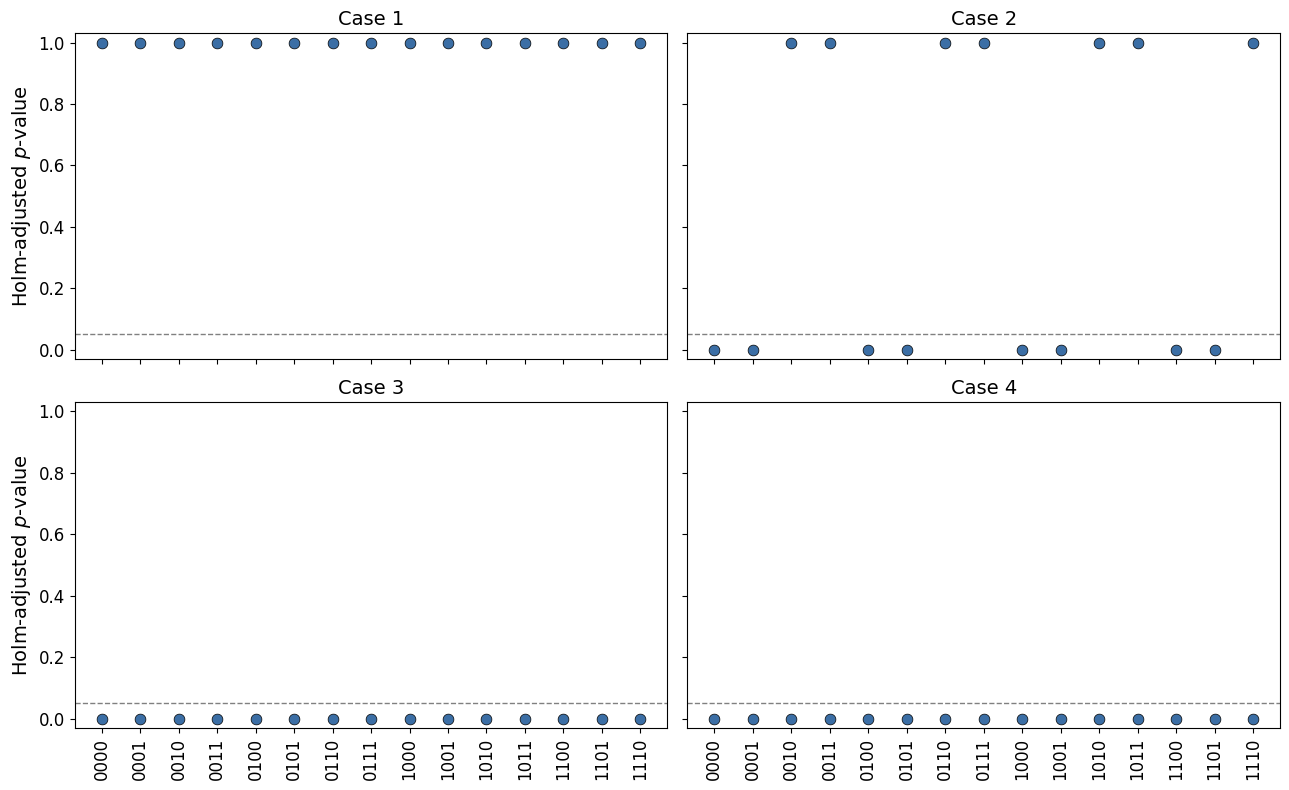

In [81]:
def config_label(bits):
    return ''.join(str(b) for b in bits)


def plot_p_holm(alpha=0.05):
    fig, axes = plt.subplots(2, 2, figsize=(13, 8), sharex=True, sharey=True)
    for ax, (case_name, rows) in zip(axes.flat, results.items()):
        rows = [r for r in rows if r[0] != (1, 1, 1, 1)]      # Holm family: 15 non-trivial configurations
        p_holm = holm_adjust([r[2] for r in rows])
        x = np.arange(len(rows))
        ax.scatter(x, p_holm, s=60, color='#3b6ea5', edgecolor='k', linewidth=0.5, zorder=3)
        ax.axhline(alpha, color='gray', ls='--', lw=1)
        ax.set_xticks(x)
        ax.set_xticklabels([config_label(r[0]) for r in rows], rotation=90)
        ax.tick_params(axis='both', labelsize=12)
        ax.set_ylim(-0.03, 1.03)
        ax.set_title(case_name.split(':')[0], fontsize=14)    # "Case 1", "Case 2", ...
    for ax in axes[:, 0]:
        ax.set_ylabel('Holm-adjusted $p$-value', fontsize=14)
    plt.tight_layout()
    fig.savefig("Figures/tandem_joint_discrepancy.png", dpi=200, bbox_inches="tight")
    plt.show()


plot_p_holm()


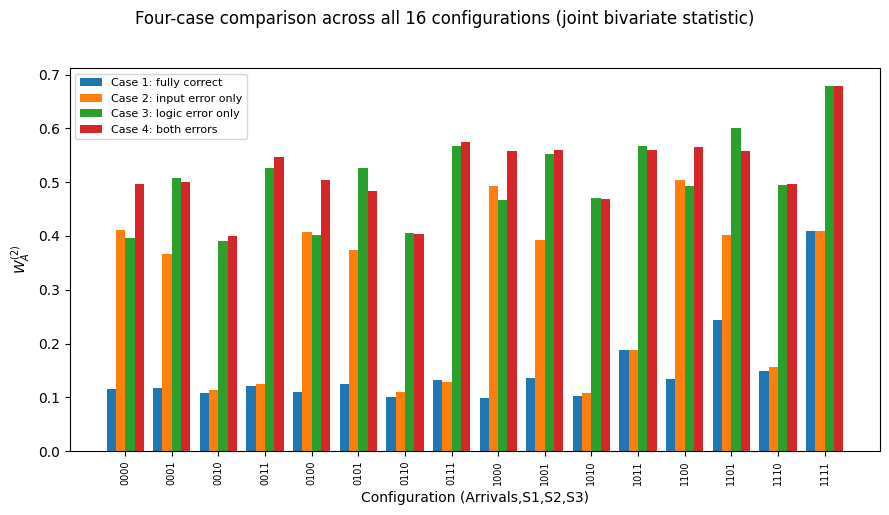

In [82]:
# 4-case comparison, isolating the two diagnostic bits (S2, S3), joint statistic
fig, ax = plt.subplots(figsize=(9, 5))
width = 0.2
x = np.arange(16)
for i, (case_name, rows) in enumerate(results.items()):
    W_list = [r[1] for r in rows]
    ax.bar(x + (i - 1.5) * width, W_list, width=width, label=case_name)
ax.set_xticks(x)
ax.set_xticklabels([config_label(r[0]) for r in results['Case 1: fully correct']], rotation=90, fontsize=7)
ax.set_xlabel('Configuration (Arrivals,S1,S2,S3)'); ax.set_ylabel('$W_A^{(2)}$')
ax.legend(fontsize=8)
fig.suptitle('Four-case comparison across all 16 configurations (joint bivariate statistic)', y=1.02)
plt.tight_layout(); plt.show()

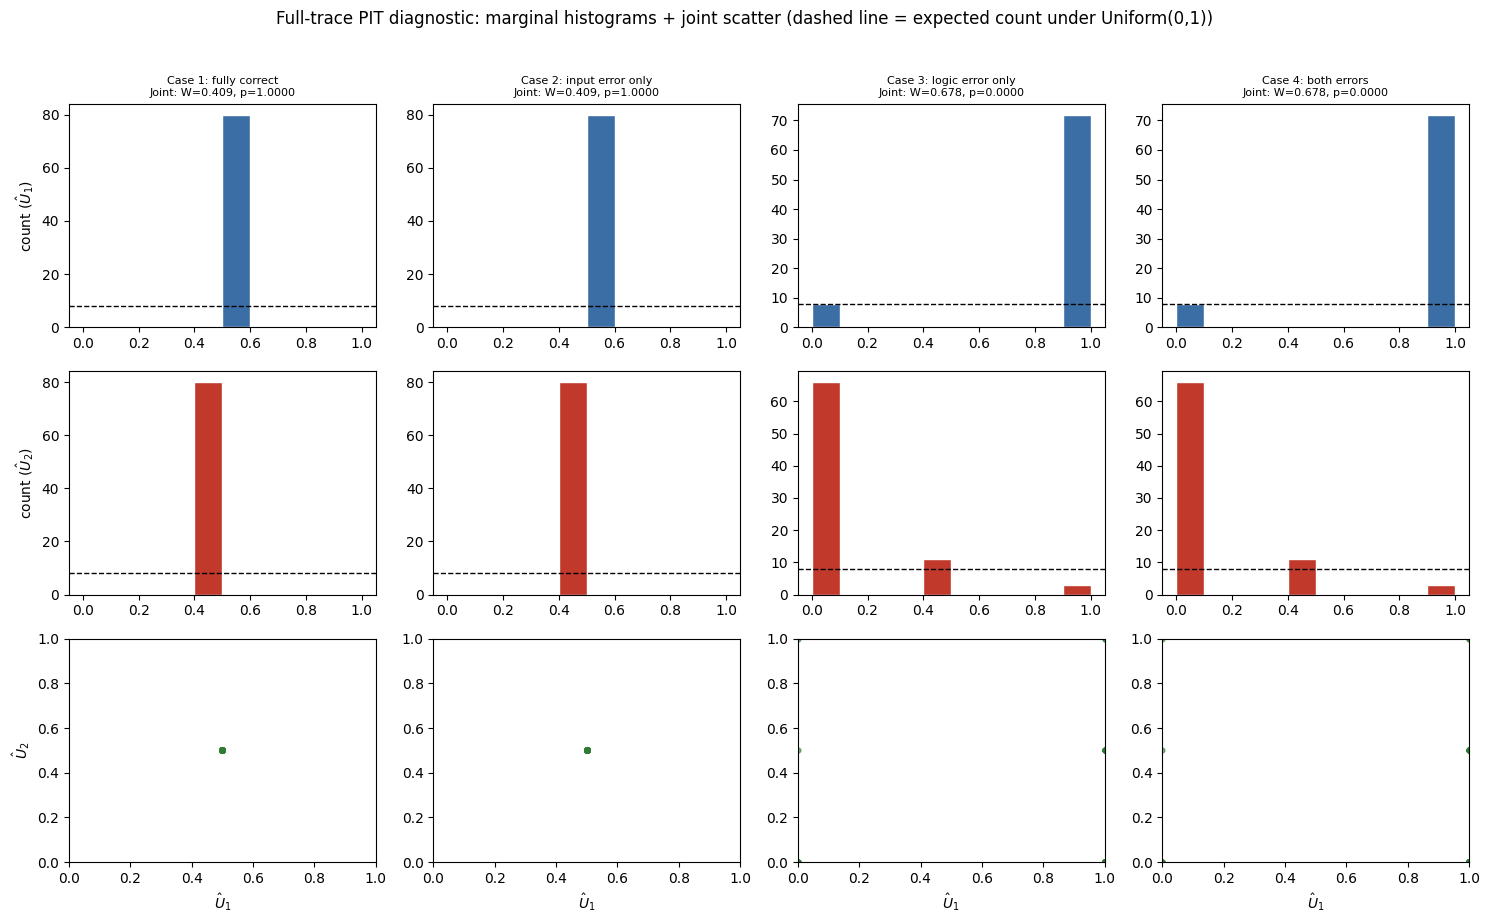

In [83]:
# Full-trace PIT diagnostic (the logic-validation test, Section 2.4): marginal histograms
# of each Rosenblatt coordinate (still useful visually) + the joint scatter that the
# W_A^(2)/p reported here actually tests.
fig, axes = plt.subplots(3, 4, figsize=(15, 9))
for col, case_name in enumerate(CASES):
    rows = results[case_name]
    full_row = [r for r in rows if r[0] == (1, 1, 1, 1)][0]
    bits = full_row[0]
    U1, U2, _, _, _ = simulate_config_pit(bits, R_REPS, T_PERIODS, PERIOD_LEN, CASES[case_name]['buffers'],
                                           ARRIVAL_RATE, CASES[case_name]['cand_means'],
                                           psi_list, arrival_hist, service_hist, y_obs1, y_obs2, rng)
    Wv, pv = full_row[1], full_row[2]
    axes[0, col].hist(U1, bins=10, range=(0, 1), color='#3b6ea5', edgecolor='white')
    axes[0, col].axhline(T_PERIODS / 10, color='k', ls='--', lw=1)
    axes[0, col].set_title(f'{case_name}\nJoint: W={Wv:.3f}, p={pv:.4f}', fontsize=8)
    axes[1, col].hist(U2, bins=10, range=(0, 1), color='#c0392b', edgecolor='white')
    axes[1, col].axhline(T_PERIODS / 10, color='k', ls='--', lw=1)
    axes[2, col].scatter(U1, U2, s=12, alpha=0.6, color='#2e7d32')
    axes[2, col].set_xlim(0, 1); axes[2, col].set_ylim(0, 1)
    axes[2, col].set_xlabel('$\\hat U_1$')
axes[0, 0].set_ylabel('count ($\\hat U_1$)')
axes[1, 0].set_ylabel('count ($\\hat U_2$)')
axes[2, 0].set_ylabel('$\\hat U_2$')
fig.suptitle('Full-trace PIT diagnostic: marginal histograms + joint scatter '
             '(dashed line = expected count under Uniform(0,1))', y=1.02)
plt.tight_layout(); plt.show()

## 6b. Testing Simulation Logic (full-trace exceedance test)

Before the DoE-based misalignment attribution below, we apply a separate,
non-statistical **full-trace logic test**: fix the entire historical trace
(`A^c = empty`, i.e. `bits=(1,1,1,1)`) and compare the candidate logic's output
`ytilde_t = H^sim(psi_t, xi_t)` against the real `y_t`, for each of the four
cases. Because no stochastic inputs are simulated in this configuration,
`d_t = y_t - ytilde_t` directly reflects the discrepancy attributable to the
simulation logic itself, isolated from any input-model error. For a
user-specified tolerance `epsilon_log` (set separately per output) we report
the empirical exceedance proportion

```
rho_hat_log(epsilon_log) = (1/T) * sum_t 1(|d_t| > epsilon_log)
```

against a second user-specified threshold `gamma_log` (also set separately per
output): a case's logic is acceptable for an output when
`rho_hat_log <= gamma_log`. This reuses the already-simulated
`reps_all[case][(1,1,1,1)]` replicates from Section 4 -- no new simulation.


In [84]:
# --- Testing Simulation Logic: full-trace exceedance test ---
# Two user-defined thresholds per output: a tolerance (epsilon_log) on the full-trace
# discrepancy d_t = y_t - ytilde_t, and a max acceptable exceedance proportion (gamma_log).
EPSILON_LOG1 = 1.5   # Y1 (mean wait, minutes) tolerance
GAMMA_LOG1 = 0.05      # Y1 max acceptable proportion of periods with |d_t| > EPSILON_LOG1

EPSILON_LOG2 = 0.1    # Y2 (balk fraction) tolerance
GAMMA_LOG2 = 0.05     # Y2 max acceptable proportion of periods with |d_t| > EPSILON_LOG2


def logic_exceedance_test(case_name, eps1, eps2):
    '''Full-trace logic test: A^c=empty, i.e. bits=(1,1,1,1), reusing reps_all (no new
    simulation). ytilde_t is the mean over the R full-trace replicates -- exact for Case 1/2
    (true buffer: replay is deterministic, so all R replicates are identical), and only an
    approximation for Case 3/4 if the wrong buffer ever forces a fallback draw (flagged via
    max_std below, expected to be ~0 per the fallback-count discussion in Section 4).'''
    reps1, reps2 = reps_all[case_name][(1, 1, 1, 1)]
    max_std = max(reps1.std(axis=1).max(), reps2.std(axis=1).max())

    ytilde1 = reps1.mean(axis=1)
    ytilde2 = reps2.mean(axis=1)
    d1 = y_obs1 - ytilde1
    d2 = y_obs2 - ytilde2

    rho_log1 = np.mean(np.abs(d1) > eps1)
    rho_log2 = np.mean(np.abs(d2) > eps2)
    return rho_log1, rho_log2, max_std


logic_test_rows = []
for case_name in CASES:
    rho_log1, rho_log2, max_std = logic_exceedance_test(case_name, EPSILON_LOG1, EPSILON_LOG2)
    logic_test_rows.append({
        'Case': case_name,
        'rho_hat_log (Y1)': round(rho_log1, 4),
        'Accept (Y1)': bool(rho_log1 <= GAMMA_LOG1),
        'rho_hat_log (Y2)': round(rho_log2, 4),
        'Accept (Y2)': bool(rho_log2 <= GAMMA_LOG2),
    })
    if max_std > 1e-6:
        print(f'{case_name}: full-trace replicates are not exactly deterministic '
              f'(max std across R = {max_std:.2e}) -- ytilde_t used the across-R mean.')

logic_test_df = pd.DataFrame(logic_test_rows)
display(logic_test_df)


,Case,rho_hat_log (Y1),Accept (Y1),rho_hat_log (Y2),Accept (Y2)
0,Case 1: fully correct,0.0000,True,0.0,True
1,Case 2: input error only,0.0000,True,0.0,True
2,Case 3: logic error only,0.2125,False,0.7,False
3,Case 4: both errors,0.2125,False,0.7,False


,Case,rho_hat_log (Y1),Accept (Y1),rho_hat_log (Y2),Accept (Y2)
0,Case 1: fully correct,0.0000,True,0.0,True
1,Case 2: input error only,0.0000,True,0.0,True
2,Case 3: logic error only,0.0125,True,0.7,False
3,Case 4: both errors,0.0125,True,0.7,False


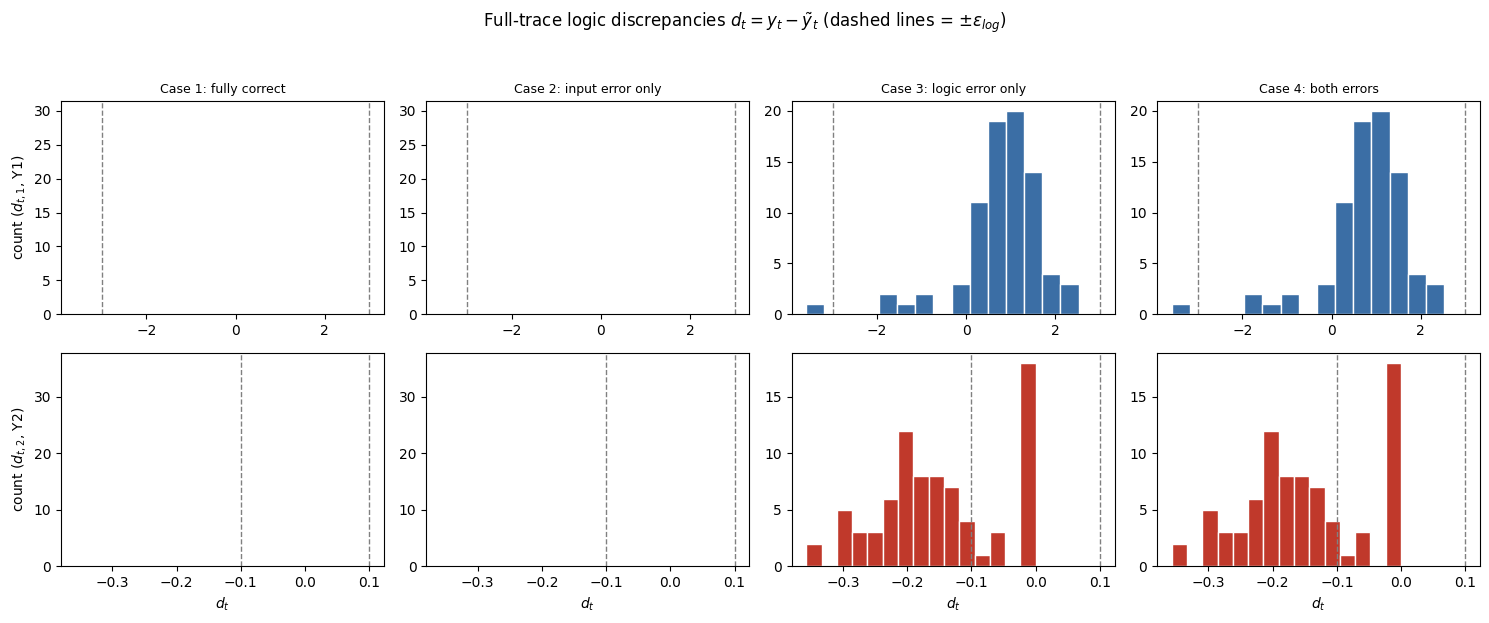

In [85]:
# --- Testing Simulation Logic: full-trace exceedance test ---
# Two user-defined thresholds per output: a tolerance (epsilon_log) on the full-trace
# discrepancy d_t = y_t - ytilde_t, and a max acceptable exceedance proportion (gamma_log).
EPSILON_LOG1 = 3.0    # Y1 (mean wait, minutes) tolerance
GAMMA_LOG1 = 0.05      # Y1 max acceptable proportion of periods with |d_t| > EPSILON_LOG1

EPSILON_LOG2 = 0.1    # Y2 (balk fraction) tolerance
GAMMA_LOG2 = 0.05      # Y2 max acceptable proportion of periods with |d_t| > EPSILON_LOG2


def logic_exceedance_test(case_name, eps1, eps2):
    '''Full-trace logic test: A^c=empty, i.e. bits=(1,1,1,1), reusing reps_all (no new
    simulation). ytilde_t is the mean over the R full-trace replicates -- exact for Case 1/2
    (true buffer: replay is deterministic, so all R replicates are identical), and only an
    approximation for Case 3/4 if the wrong buffer ever forces a fallback draw (flagged via
    max_std below, expected to be ~0 per the fallback-count discussion in Section 4).'''
    reps1, reps2 = reps_all[case_name][(1, 1, 1, 1)]
    max_std = max(reps1.std(axis=1).max(), reps2.std(axis=1).max())

    ytilde1 = reps1.mean(axis=1)
    ytilde2 = reps2.mean(axis=1)
    d1 = y_obs1 - ytilde1
    d2 = y_obs2 - ytilde2

    rho_log1 = np.mean(np.abs(d1) > eps1)
    rho_log2 = np.mean(np.abs(d2) > eps2)
    return rho_log1, rho_log2, max_std, d1, d2


logic_test_rows = []
logic_test_diffs = {}
for case_name in CASES:
    rho_log1, rho_log2, max_std, d1, d2 = logic_exceedance_test(case_name, EPSILON_LOG1, EPSILON_LOG2)
    logic_test_diffs[case_name] = (d1, d2)
    logic_test_rows.append({
        'Case': case_name,
        'rho_hat_log (Y1)': round(rho_log1, 4),
        'Accept (Y1)': bool(rho_log1 <= GAMMA_LOG1),
        'rho_hat_log (Y2)': round(rho_log2, 4),
        'Accept (Y2)': bool(rho_log2 <= GAMMA_LOG2),
    })
    if max_std > 1e-6:
        print(f'{case_name}: full-trace replicates are not exactly deterministic '
              f'(max std across R = {max_std:.2e}) -- ytilde_t used the across-R mean.')

logic_test_df = pd.DataFrame(logic_test_rows)
display(logic_test_df)

# Histograms of the full-trace discrepancies d_t = y_t - ytilde_t, per case, with the
# +/-epsilon_log tolerance band marked (dashed lines).
fig, axes = plt.subplots(2, 4, figsize=(15, 6), sharex='row')
for col, case_name in enumerate(CASES):
    d1, d2 = logic_test_diffs[case_name]
    axes[0, col].hist(d1, bins=15, color='#3b6ea5', edgecolor='white')
    axes[0, col].axvline(-EPSILON_LOG1, color='gray', ls='--', lw=1)
    axes[0, col].axvline(EPSILON_LOG1, color='gray', ls='--', lw=1)
    axes[0, col].set_title(case_name, fontsize=9)
    axes[1, col].hist(d2, bins=15, color='#c0392b', edgecolor='white')
    axes[1, col].axvline(-EPSILON_LOG2, color='gray', ls='--', lw=1)
    axes[1, col].axvline(EPSILON_LOG2, color='gray', ls='--', lw=1)
    axes[1, col].set_xlabel('$d_t$')
axes[0, 0].set_ylabel('count ($d_{t,1}$, Y1)')
axes[1, 0].set_ylabel('count ($d_{t,2}$, Y2)')
fig.suptitle(r'Full-trace logic discrepancies $d_t = y_t - \tilde y_t$ '
             r'(dashed lines = $\pm\epsilon_{log}$)', y=1.03)
plt.tight_layout(); plt.show()


## 7. Diagnosing the source(s) of misalignment (Section 3 of the paper)

We now apply the paper's design-of-experiments machinery to **Cases 2, 3,
and 4** (Case 1 has no misspecification to attribute). The `2^4` full
factorial over `z_A` already gives us `{(z_A, W_A^(2))}` for each case; we
enrich it via **bootstrapping** the `R` replicates at each `(t,A)`
(Section 3.1), which lets us quantify the finite-`R` sampling uncertainty
without any new simulation runs, then fit both a linear model with main
effects and all two-way interactions, and a regression tree, on the
**single joint statistic** `W_A^(2)`.

Case 2 has no logic defect (the buffer never varies across its 16
configurations), so it is attributed with the plain 4-factor design
(Arrivals, S1, S2, S3) — a constant `Logic` column would be uninformative.
Cases 3 and 4 add a fifth column, **Logic** (`1` = candidate uses the TRUE
Station-3 buffer capacity, `0` = candidate uses the misspecified
`CAND_BUFFERS`), and one extra configuration to go with it: all four inputs
historical *and* the true buffer, i.e. the full-trace replay with no logic
error. That row is the "everything matches reality" anchor — by
construction it has the smallest `W_A^(2)` of any row in its dataset, since
it is a full-trace deterministic reproduction. Every other row already in
the dataset (the 16 configurations) gets `Logic=0`.

In [86]:
def bootstrap_biv_W(reps1_matrix, reps2_matrix, y_obs1, y_obs2, B, rng):
    """Resample each period's R paired replicates with replacement (same
    index applied to both outputs, to preserve pairing; no new simulation),
    recompute the pooled JOINT Wasserstein-2 statistic B times."""
    T, R = reps1_matrix.shape
    Ws = np.empty(B)
    for b in range(B):
        U1b = np.empty(T); U2b = np.empty(T)
        for t in range(T):
            idx = rng.integers(0, R, size=R)
            U1b[t], U2b[t] = bivariate_conditional_pit(
                reps1_matrix[t, idx], reps2_matrix[t, idx], y_obs1[t], y_obs2[t])
        Ws[b] = wasserstein2_joint(np.column_stack([U1b, U2b]))
    return Ws


def build_design_matrix(bits_list, process_names):
    Z = np.array(bits_list, dtype=float)
    n, S = Z.shape
    cols, names = [np.ones(n)], ["Intercept"]
    for s in range(S):
        cols.append(Z[:, s]); names.append(process_names[s])
    for s in range(S):
        for sp in range(s + 1, S):
            cols.append(Z[:, s] * Z[:, sp]); names.append(f"{process_names[s]}*{process_names[sp]}")
    return np.column_stack(cols), names


def build_doe_dataset(case_name, include_logic, B, rng):
    """Bootstrap-enriched DoE dataset for one case (Section 3.1). If
    include_logic, adds the Logic factor and the true-buffer/full-trace
    anchor row; otherwise (no logic defect is active in this case, so the
    buffer never varies) uses the plain 4-factor design, since a constant
    Logic column would be uninformative and not separately identifiable.

    The anchor row (bits=(1,1,1,1), Logic=1) is inserted directly as W=0
    rather than computed via simulate_config_pit/bootstrap_biv_W: its
    replicates are deterministic (a full-trace replay under the TRUE buffer
    reproduces y_obs exactly every period), which collapses
    bivariate_conditional_pit's bandwidths to their floor and forces
    (U1,U2)=(0.5,0.5) regardless of the data, so wasserstein2_joint reports
    W~0.41 (mean squared distance from the pooled points to the Halton
    reference is minimized by matching everything to the center) instead of
    the ~0 the anchor is supposed to represent."""
    doe_rows, doe_W = [], []
    for bits, (reps1, reps2) in reps_all[case_name].items():
        Wb = bootstrap_biv_W(reps1, reps2, y_obs1, y_obs2, B, rng)
        row_bits = bits + (0,) if include_logic else bits
        doe_rows.extend([row_bits] * B)
        doe_W.extend(Wb.tolist())
    if include_logic:
        doe_rows.extend([(1, 1, 1, 1, 1)] * B)
        doe_W.extend([0.0] * B)
    return np.array(doe_rows), np.array(doe_W)


B_BOOTSTRAP = 50
# Case 2 has no logic defect (buffers never vary -> no Logic factor); Cases 3 and 4
# do (buffers = CAND_BUFFERS throughout -> add the Logic factor + true-buffer anchor).
ATTRIBUTION_CASES = [
    ("Case 2: input error only", False),
    ("Case 3: logic error only", True),
    ("Case 4: both errors", True),
]

attribution_data = {}
for case_name, include_logic in ATTRIBUTION_CASES:
    names = PROCESS_NAMES + (["Logic"] if include_logic else [])
    doe_bits, doe_W = build_doe_dataset(case_name, include_logic, B_BOOTSTRAP, rng_doe)
    attribution_data[case_name] = (doe_bits, doe_W, names)
    n_configs = len(reps_all[case_name])
    anchor_note = " + 1 true-buffer anchor row" if include_logic else ""
    print(f"{case_name}: {len(doe_W)} bootstrap-enriched rows "
          f"({n_configs} configs{anchor_note}, x {B_BOOTSTRAP} draws each).")

Case 2: input error only: 800 bootstrap-enriched rows (16 configs, x 50 draws each).
Case 3: logic error only: 850 bootstrap-enriched rows (16 configs + 1 true-buffer anchor row, x 50 draws each).
Case 4: both errors: 850 bootstrap-enriched rows (16 configs + 1 true-buffer anchor row, x 50 draws each).



=== Case 2: input error only: largest-magnitude regression coefficients ===


,term,coefficient
0,Intercept,0.461723
3,S2,-0.384072
10,S2*S3,0.165761
4,S3,-0.120074
5,Arrivals*S1,0.069938
8,S1*S2,0.063119



=== Case 2: input error only: regression-tree variable importance ===


,process,importance
2,S2,0.732148
3,S3,0.111707
0,Arrivals,0.080627
1,S1,0.075519


Simulation error (RSS/df): 0.00003  (RSS=0.0240, df=784)


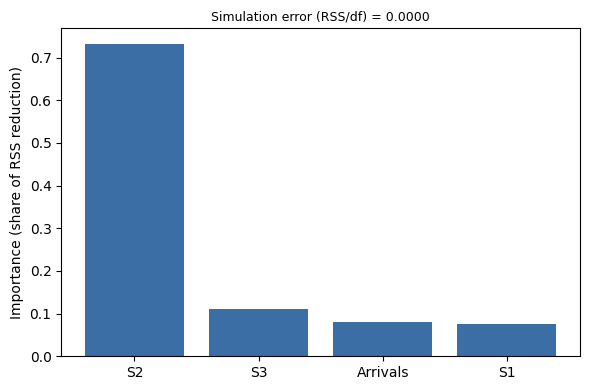


=== Case 3: logic error only: largest-magnitude regression coefficients ===


,term,coefficient
0,Intercept,0.407754
14,S2*Logic,-0.132340
15,S3*Logic,-0.132340
9,Arrivals*Logic,-0.132340
12,S1*Logic,-0.132340
5,Logic,-0.132340



=== Case 3: logic error only: regression-tree variable importance ===


,process,importance
4,Logic,0.719984
3,S3,0.183405
0,Arrivals,0.069245
1,S1,0.023022
2,S2,0.004345


Simulation error (RSS/df): 0.00028  (RSS=0.2335, df=841)


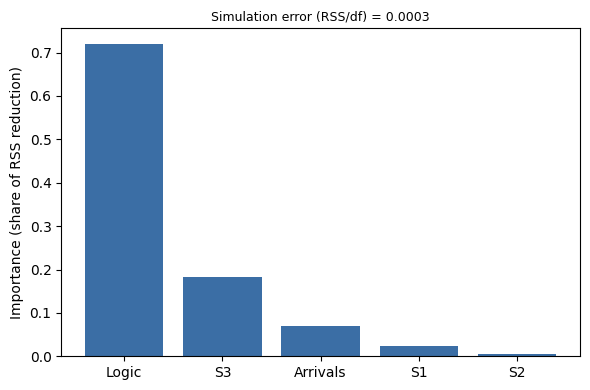


=== Case 4: both errors: largest-magnitude regression coefficients ===


,term,coefficient
0,Intercept,0.511642
13,S2*S3,0.152166
15,S3*Logic,-0.131736
5,Logic,-0.131736
14,S2*Logic,-0.131736
12,S1*Logic,-0.131736



=== Case 4: both errors: regression-tree variable importance ===


,process,importance
4,Logic,0.801809
2,S2,0.074881
0,Arrivals,0.061865
3,S3,0.061444
1,S1,0.000000


Simulation error (RSS/df): 0.00048  (RSS=0.4031, df=841)


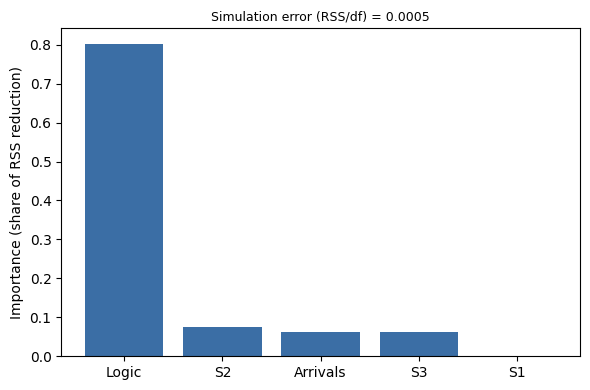

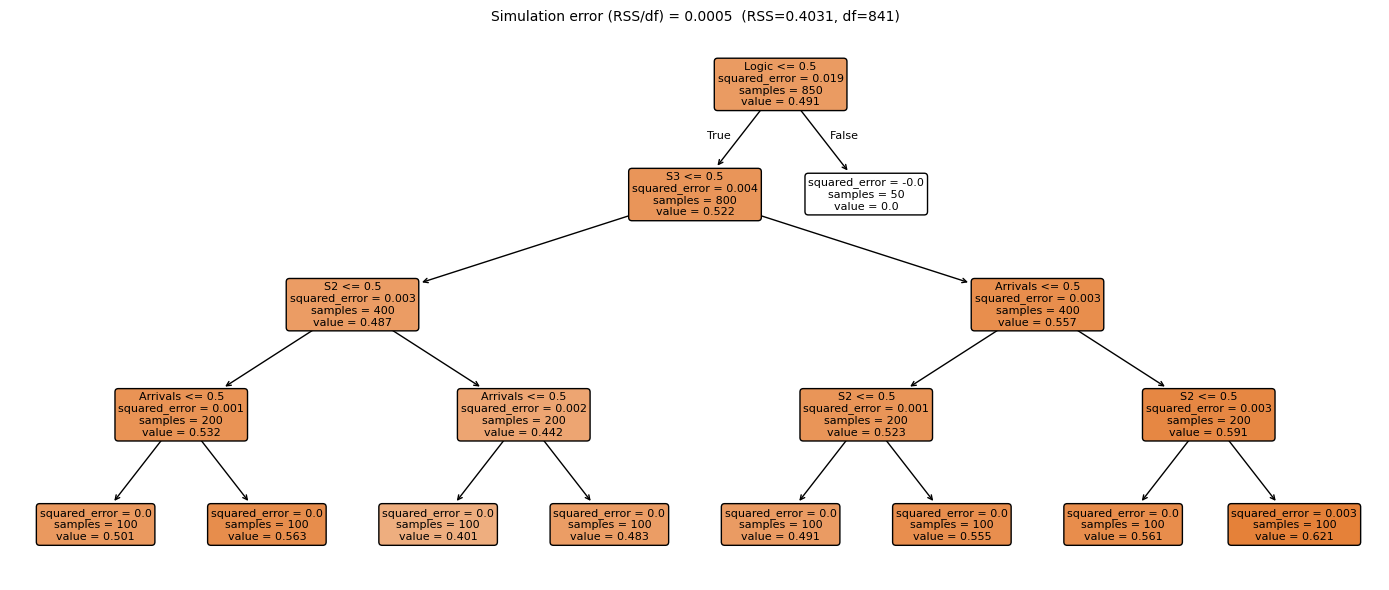

In [87]:
def tree_sim_error(tree, X, y):
    '''Residual variance left unexplained by the tree\'s bits-based splits: RSS / df, with
    df = n_rows - n_splits - 1 (n_splits = number of internal/decision nodes). Every sklearn
    tree split is binary, so n_splits + 1 = n_leaves, making this equivalent to n_rows - n_leaves
    -- the usual one-way-ANOVA residual df for a piecewise-constant fit with one mean per leaf.
    Reported as the "simulation error": how much of doe_W\'s bootstrap-induced spread the tree\'s
    bits-only splits cannot explain.'''
    resid = y - tree.predict(X)
    rss = np.sum(resid ** 2)
    n_splits = tree.tree_.node_count - tree.get_n_leaves()
    df = len(y) - n_splits - 1
    return rss / df, rss, df


attribution_importances = {}
for case_name, (doe_bits, doe_W, names) in attribution_data.items():
    X, term_names = build_design_matrix(doe_bits, names)
    beta, *_ = np.linalg.lstsq(X, doe_W, rcond=None)
    coef_df = pd.DataFrame({"term": term_names, "coefficient": beta}).sort_values(
        "coefficient", key=np.abs, ascending=False)
    print(f"\n=== {case_name}: largest-magnitude regression coefficients ===")
    display(coef_df.head(6))

    tree = DecisionTreeRegressor(max_depth=4, min_samples_leaf=20, random_state=SEED)
    tree.fit(doe_bits, doe_W)
    sim_err, rss, df = tree_sim_error(tree, doe_bits, doe_W)
    importances = pd.DataFrame({"process": names, "importance": tree.feature_importances_}) \
        .sort_values("importance", ascending=False)
    attribution_importances[case_name] = importances
    print(f"\n=== {case_name}: regression-tree variable importance ===")
    display(importances)
    print(f"Simulation error (RSS/df): {sim_err:.5f}  (RSS={rss:.4f}, df={df})")

    case_num = case_name.split(":")[0].split()[-1]
    fig, ax = plt.subplots(figsize=(6, 4))
    ax.bar(importances["process"], importances["importance"], color="#3b6ea5")
    ax.set_ylabel("Importance (share of RSS reduction)")
    ax.set_title(f"Simulation error (RSS/df) = {sim_err:.4f}", fontsize=9)
    plt.tight_layout()
    fig.savefig(f"Figures/tandem_tree_importance_case{case_num}.png", dpi=200, bbox_inches="tight")
    plt.show()

# Full tree diagram kept for Case 4 only (the main case).
doe_bits4, doe_W4, names4 = attribution_data["Case 4: both errors"]
tree4 = DecisionTreeRegressor(max_depth=4, min_samples_leaf=20, random_state=SEED)
tree4.fit(doe_bits4, doe_W4)
sim_err4, rss4, df4 = tree_sim_error(tree4, doe_bits4, doe_W4)
fig, ax = plt.subplots(figsize=(14, 6))
plot_tree(tree4, feature_names=names4, filled=True, rounded=True, fontsize=8, ax=ax)
ax.set_title(f"Simulation error (RSS/df) = {sim_err4:.4f}  (RSS={rss4:.4f}, df={df4})", fontsize=10)
plt.tight_layout()
fig.savefig("Figures/tandem_tree_diagram_case4.png", dpi=200, bbox_inches="tight")
plt.show()



=== Case 2: input error only: largest-magnitude regression coefficients ===


,term,coefficient
0,Intercept,0.461723
3,S2,-0.384072
10,S2*S3,0.165761
4,S3,-0.120074
5,Arrivals*S1,0.069938
8,S1*S2,0.063119



=== Case 2: input error only: regression-tree variable importance ===


,process,importance
2,S2,0.732148
3,S3,0.111707
0,Arrivals,0.080627
1,S1,0.075519


Simulation error (RSS/df): 0.00003  (RSS=0.0240, df=784)


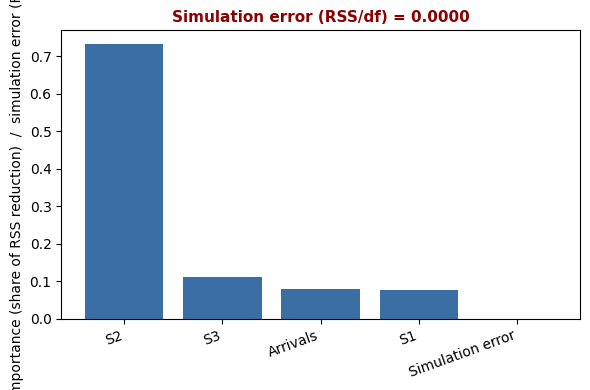


=== Case 3: logic error only: largest-magnitude regression coefficients ===


,term,coefficient
0,Intercept,0.407754
14,S2*Logic,-0.132340
15,S3*Logic,-0.132340
9,Arrivals*Logic,-0.132340
12,S1*Logic,-0.132340
5,Logic,-0.132340



=== Case 3: logic error only: regression-tree variable importance ===


,process,importance
4,Logic,0.719984
3,S3,0.183405
0,Arrivals,0.069245
1,S1,0.023022
2,S2,0.004345


Simulation error (RSS/df): 0.00028  (RSS=0.2335, df=841)


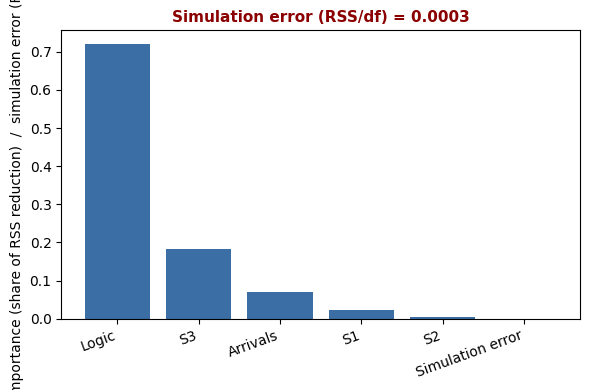


=== Case 4: both errors: largest-magnitude regression coefficients ===


,term,coefficient
0,Intercept,0.511642
13,S2*S3,0.152166
15,S3*Logic,-0.131736
5,Logic,-0.131736
14,S2*Logic,-0.131736
12,S1*Logic,-0.131736



=== Case 4: both errors: regression-tree variable importance ===


,process,importance
4,Logic,0.801809
2,S2,0.074881
0,Arrivals,0.061865
3,S3,0.061444
1,S1,0.000000


Simulation error (RSS/df): 0.00048  (RSS=0.4031, df=841)


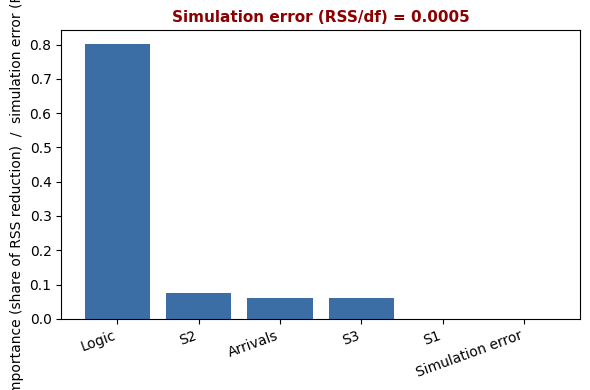

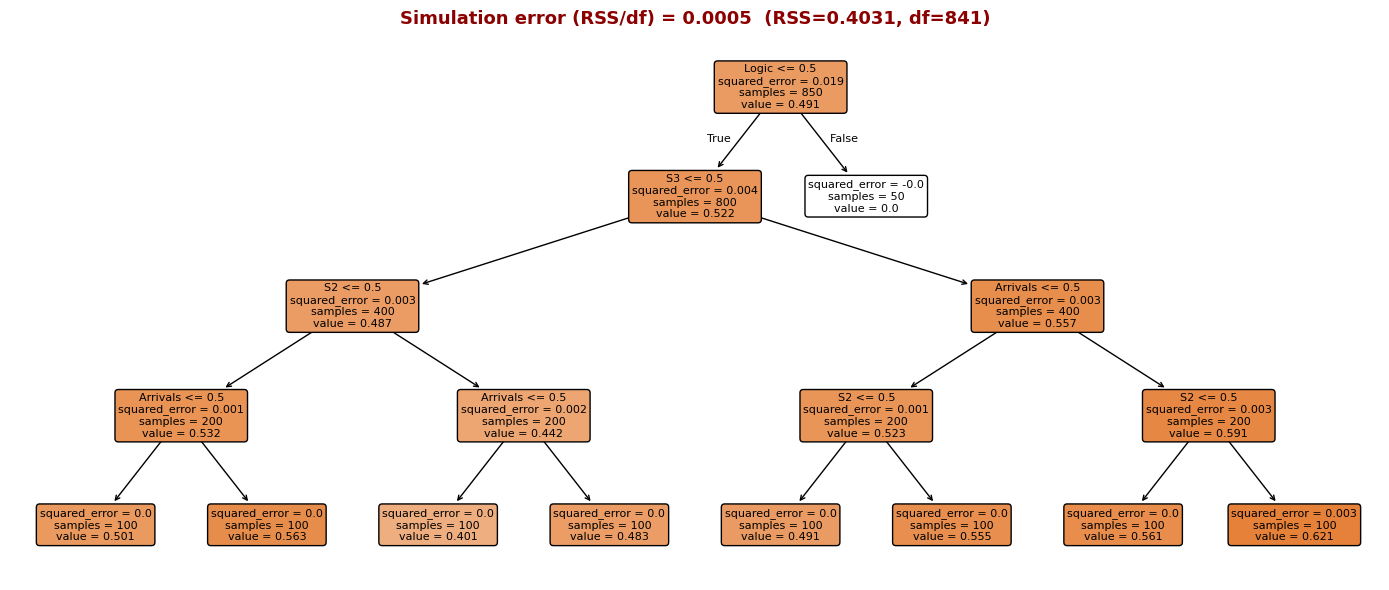

In [94]:
def tree_sim_error(tree, X, y):
    '''Residual variance left unexplained by the tree's bits-based splits: RSS / df, with
    df = n_rows - n_splits - 1 (n_splits = number of internal/decision nodes). Every sklearn
    tree split is binary, so n_splits + 1 = n_leaves, making this equivalent to n_rows - n_leaves
    -- the usual one-way-ANOVA residual df for a piecewise-constant fit with one mean per leaf.
    Reported as the "simulation error": how much of doe_W's bootstrap-induced spread the tree's
    bits-only splits cannot explain.'''
    resid = y - tree.predict(X)
    rss = np.sum(resid ** 2)
    n_splits = tree.tree_.node_count - tree.get_n_leaves()
    df = len(y) - n_splits - 1
    return rss / df, rss, df


attribution_importances = {}
for case_name, (doe_bits, doe_W, names) in attribution_data.items():
    X, term_names = build_design_matrix(doe_bits, names)
    beta, *_ = np.linalg.lstsq(X, doe_W, rcond=None)
    coef_df = pd.DataFrame({"term": term_names, "coefficient": beta}).sort_values(
        "coefficient", key=np.abs, ascending=False)
    print(f"\n=== {case_name}: largest-magnitude regression coefficients ===")
    display(coef_df.head(6))

    tree = DecisionTreeRegressor(max_depth=4, min_samples_leaf=20, random_state=SEED)
    tree.fit(doe_bits, doe_W)
    sim_err, rss, df = tree_sim_error(tree, doe_bits, doe_W)
    importances = pd.DataFrame({"process": names, "importance": tree.feature_importances_}) \
        .sort_values("importance", ascending=False)
    attribution_importances[case_name] = importances
    print(f"\n=== {case_name}: regression-tree variable importance ===")
    display(importances)
    print(f"Simulation error (RSS/df): {sim_err:.5f}  (RSS={rss:.4f}, df={df})")

    case_num = case_name.split(":")[0].split()[-1]
    bar_labels = list(importances["process"]) + ["Simulation error"]
    bar_values = list(importances["importance"]) + [sim_err]
    bar_colors = ["#3b6ea5"] * len(importances) + ["#8b0000"]
    fig, ax = plt.subplots(figsize=(6, 4))
    ax.bar(bar_labels, bar_values, color=bar_colors)
    ax.set_ylabel("Importance (share of RSS reduction)  /  simulation error (RSS/df)")
    ax.set_title(f"Simulation error (RSS/df) = {sim_err:.4f}",
                 fontsize=11, fontweight="bold", color="#8b0000")
    plt.xticks(rotation=20, ha="right")
    plt.tight_layout()
    fig.savefig(f"Figures/tandem_tree_importance_case{case_num}.png", dpi=200, bbox_inches="tight")
    plt.show()

# Full tree diagram kept for Case 4 only (the main case).
doe_bits4, doe_W4, names4 = attribution_data["Case 4: both errors"]
tree4 = DecisionTreeRegressor(max_depth=4, min_samples_leaf=20, random_state=SEED)
tree4.fit(doe_bits4, doe_W4)
sim_err4, rss4, df4 = tree_sim_error(tree4, doe_bits4, doe_W4)
fig, ax = plt.subplots(figsize=(14, 6))
plot_tree(tree4, feature_names=names4, filled=True, rounded=True, fontsize=8, ax=ax)
ax.set_title(f"Simulation error (RSS/df) = {sim_err4:.4f}  (RSS={rss4:.4f}, df={df4})",
             fontsize=13, fontweight="bold", color="#8b0000")
plt.tight_layout()
fig.savefig("Figures/tandem_tree_diagram_case4.png", dpi=200, bbox_inches="tight")
plt.show()


In [88]:
attribution_datasets = {}
for case_name, (doe_bits, doe_W, names) in attribution_data.items():
    df = pd.DataFrame(doe_bits, columns=names)
    df["W_A^(2)"] = doe_W
    attribution_datasets[case_name] = df
    print(f"{case_name}: {df.shape[0]} rows, columns = {names}")
    display(df)

Case 2: input error only: 800 rows, columns = ['Arrivals', 'S1', 'S2', 'S3']


,Arrivals,S1,S2,S3,W_A^(2)
0,0,0,0,0,0.408707
1,0,0,0,0,0.417397
2,0,0,0,0,0.414169
3,0,0,0,0,0.417428
4,0,0,0,0,0.400952
...,...,...,...,...,...
795,1,1,1,1,0.409490
796,1,1,1,1,0.409490
797,1,1,1,1,0.409490
798,1,1,1,1,0.409490


Case 3: logic error only: 850 rows, columns = ['Arrivals', 'S1', 'S2', 'S3', 'Logic']


,Arrivals,S1,S2,S3,Logic,W_A^(2)
0,0,0,0,0,0,0.393589
1,0,0,0,0,0,0.399057
2,0,0,0,0,0,0.401574
3,0,0,0,0,0,0.406837
4,0,0,0,0,0,0.398587
...,...,...,...,...,...,...
845,1,1,1,1,1,0.000000
846,1,1,1,1,1,0.000000
847,1,1,1,1,1,0.000000
848,1,1,1,1,1,0.000000


Case 4: both errors: 850 rows, columns = ['Arrivals', 'S1', 'S2', 'S3', 'Logic']


,Arrivals,S1,S2,S3,Logic,W_A^(2)
0,0,0,0,0,0,0.496537
1,0,0,0,0,0,0.504716
2,0,0,0,0,0,0.496887
3,0,0,0,0,0,0.501631
4,0,0,0,0,0,0.493731
...,...,...,...,...,...,...
845,1,1,1,1,1,0.000000
846,1,1,1,1,1,0.000000
847,1,1,1,1,1,0.000000
848,1,1,1,1,1,0.000000


## 8. Practical significance via Wasserstein perturbation

The joint test above asks whether the candidate model is *statistically* distinguishable from the system.
Here we ask whether the misalignment is *practically* significant. You pick two tolerances in output units:

* `DELTA_1`: how far (in $W_1$, minutes) the distribution of $Y_1$ = mean waiting time may be off;
* `DELTA_2`: how far (in $W_1$, balk fraction) the distribution of $Y_2$ = balk fraction **given** the observed $Y_1$ may be off.

For each period, every distribution within these tolerances of the KDE estimate
$\widehat F_{t,A,1}$, $\widehat F_{t,A,2\mid1}(\cdot\mid y_{t1})$ gives a PIT pair, so the attainable PIT pairs form a box
$[\underline U_{t1},\overline U_{t1}]\times[\underline U_{t2},\overline U_{t2}]$. The box edges come from the paper's
$y^\pm_t(\delta_j)$ formulas. The transport cost $\int_y^{y_t}(y_t-h)\hat f(h)\,dh$ is closed form for the Gaussian-mixture KDE,
and its root is found by bisection. Then

$$W_A^{\star,(2)}(\boldsymbol\delta)=\min_{\widetilde{\mathbf U}_t\in\text{box}_t} W_2\Big(\tfrac1T\textstyle\sum_t\delta_{\widetilde{\mathbf U}_t},\ \text{Halton reference}\Big).$$

For a fixed matching, the best point in box $t$ is its reference point clipped into the box, so this is one exact assignment problem.

**Decision.** We use the same statistic and the same per-configuration LOO null as the joint test:
$p^\star_A=\Pr_{\text{null}}\{W\ge W_A^{\star,(2)}(\boldsymbol\delta)\}$, Holm-adjusted over the 15 non-trivial configurations.
$H_0(\boldsymbol\delta)$ ("the misalignment is within the tolerances") is rejected when the Holm-adjusted $p^\star_A<\alpha$.
By the Type I error proposition, this controls the error rate because $W_A^{\star,(2)}(\boldsymbol\delta)$ can only be smaller than the statistic of the
true PITs. With $\boldsymbol\delta=\mathbf 0$ the boxes shrink to points and the test is exactly the joint test of Section 4.

The full-trace configuration (all inputs historical) is left out. Its replications are deterministic, so its PIT
is degenerate (it is the logic test, handled separately above).

In [89]:
# ---- practical-significance tolerances (output units)
DELTA_1 = 1.5     # Y1 = mean waiting time: tolerated W1 discrepancy, in minutes
DELTA_2 = 0.05    # Y2 = balk fraction given Y1: tolerated W1 discrepancy (0.02 = 2 percentage points)
ALPHA_PS = 0.05
CASE_PS = 'Case 4: both errors'   # case shown in the detailed table

In [90]:
from scipy.special import ndtr

assert W_METHOD == "fast", "the practical test uses the T-point Halton reference (W_METHOD = 'fast')"


def _npdf(z):
    return np.exp(-0.5 * z * z) / np.sqrt(2 * np.pi)


def rosenblatt_mixtures(reps1, reps2, y1):
    '''Same KDE as bivariate_conditional_pit, returned as Gaussian mixtures (weights, means, common sd) per period:
    F_hat_1 (marginal of Y1) and F_hat_{2|1}(. | y_t1) (Y2 given the observed Y1).'''
    T, R = reps1.shape
    w2, m2, s1, s2 = np.empty((T, R)), np.empty((T, R)), np.empty(T), np.empty(T)
    for t in range(T):
        H = _fit_bivariate_kde(reps1[t], reps2[t])
        s1[t] = np.sqrt(H[0, 0])
        w2[t] = _safe_normalize(norm.pdf((y1[t] - reps1[t]) / s1[t]))
        m2[t] = reps2[t] + H[0, 1] / H[0, 0] * (y1[t] - reps1[t])
        s2[t] = np.sqrt(max(H[1, 1] - H[0, 1] ** 2 / H[0, 0], 1e-12))
    return (np.full((T, R), 1.0 / R), reps1, s1), (w2, m2, s2)


def pit_bounds(y, mix, delta, iters=60):
    '''[inf F(y_t), sup F(y_t)] over the W1 ball of radius delta around the mixture F_hat_t, for all t at once.'''
    w, m, s = mix
    S, Y = s[:, None], y[:, None]
    cdf = lambda x: (w * ndtr((x[:, None] - m) / S)).sum(1)
    if delta == 0:
        F = cdf(y)
        return F, F
    zy = (Y - m) / S
    Fy, py = ndtr(zy), _npdf(zy)
    cost_lo = lambda a: (w * ((Y - m) * (Fy - ndtr((a[:, None] - m) / S)) + S * (py - _npdf((a[:, None] - m) / S)))).sum(1)
    cost_hi = lambda b: (w * ((m - Y) * (ndtr((b[:, None] - m) / S) - Fy) + S * (py - _npdf((b[:, None] - m) / S)))).sum(1)
    a_lo, a_hi = m.min(1) - 12 * s, y.astype(float).copy()   # y^-: smallest a <= y_t with cost_lo(a) <= delta
    b_lo, b_hi = y.astype(float).copy(), m.max(1) + 12 * s   # y^+: largest  b >= y_t with cost_hi(b) <= delta
    for _ in range(iters):
        a = (a_lo + a_hi) / 2
        over = cost_lo(a) > delta
        a_lo, a_hi = np.where(over, a, a_lo), np.where(over, a_hi, a)
        b = (b_lo + b_hi) / 2
        over = cost_hi(b) > delta
        b_lo, b_hi = np.where(over, b_lo, b), np.where(over, b, b_hi)
    return cdf(a_hi), cdf(b_lo)


def w_star(lo, hi, ref=JOINT_REF):
    '''min of the joint statistic over U_t in [lo_t, hi_t]; for a fixed matching the best U_t is ref_i clipped into box t.'''
    P = np.clip(ref[None, :, :], lo[:, None, :], hi[:, None, :])
    C = ((P - ref[None, :, :]) ** 2).sum(2)
    r, c = linear_sum_assignment(C)
    return np.sqrt(C[r, c].mean())


def practical_W(case_name, bits, d1, d2):
    reps1, reps2 = reps_all[case_name][bits]
    mix1, mix2 = rosenblatt_mixtures(reps1, reps2, y_obs1)
    l1, h1 = pit_bounds(y_obs1, mix1, d1)
    l2, h2 = pit_bounds(y_obs2, mix2, d2)
    return w_star(np.column_stack([l1, l2]), np.column_stack([h1, h2]))


# consistency check: with zero tolerances W* must equal the joint statistic W_A^(2) of Section 4
_b = (0, 0, 0, 0)
_W0 = practical_W(CASE_PS, _b, 0.0, 0.0)
_W_main = dict((r[0], r[1]) for r in results[CASE_PS])[_b]
assert abs(_W0 - _W_main) < 1e-8, (_W0, _W_main)
print(f"check passed: W*(0, 0) = {_W0:.4f} = W_A^(2) = {_W_main:.4f}")

check passed: W*(0, 0) = 0.4974 = W_A^(2) = 0.4974


In [91]:
FULL_TRACE = (1, 1, 1, 1)
configs = [b for b in ALL_BITS if b != FULL_TRACE]
H_S = lambda b: ' '.join(f"{n}={'H' if x else 'S'}" for n, x in zip(PROCESS_NAMES, b))

ps_rows = []
for case_name in CASES:
    W_main = dict((r[0], r[1]) for r in results[case_name])
    p_star = []
    for bits in configs:
        Ws = practical_W(case_name, bits, DELTA_1, DELTA_2)
        p_star.append(np.mean(null_W_all[bits] >= Ws))
        ps_rows.append(dict(case=case_name, config=H_S(bits), W_A2=W_main[bits],
                            reject_stat=bool(summary_tables[case_name]['Reject'].iloc[ALL_BITS.index(bits)]),
                            W_star=Ws))
    p_holm = holm_adjust(p_star)
    for row, p, ph in zip(ps_rows[-len(configs):], p_star, p_holm):
        row.update(p_star=p, p_star_holm=ph, reject=ph < ALPHA_PS)
ps = pd.DataFrame(ps_rows)

print(f"Tolerances: DELTA_1 = {DELTA_1} min (waiting time),  DELTA_2 = {DELTA_2} (balk fraction | waiting time),"
      f"  alpha = {ALPHA_PS}, Holm over {len(configs)} configurations  (H = historical, S = simulated)\n")

# overview: number of configurations rejected per case
overview = ps.groupby('case', sort=False).agg(
    statistically_significant=('reject_stat', 'sum'), practically_significant=('reject', 'sum'))
display(overview)

# detail for the chosen case
detail = ps[ps.case == CASE_PS].drop(columns='case').set_index('config')
detail = detail.rename(columns={'W_A2': 'W_A^(2)', 'W_star': 'W*(delta)', 'p_star': 'p*', 'p_star_holm': 'p* Holm',
                                'reject_stat': 'stat. signif.', 'reject': 'REJECT (practical)'})
print(f"\n=== {CASE_PS} ===")
display(detail.round(4))

Tolerances: DELTA_1 = 1.5 min (waiting time),  DELTA_2 = 0.05 (balk fraction | waiting time),  alpha = 0.05, Holm over 15 configurations  (H = historical, S = simulated)



,statistically_significant,practically_significant
case,,
Case 1: fully correct,0,0
Case 2: input error only,8,0
Case 3: logic error only,15,0
Case 4: both errors,15,5



=== Case 4: both errors ===


,W_A^(2),stat. signif.,W*(delta),p*,p* Holm,REJECT (practical)
config,,,,,,
Arrivals=S S1=S S2=S S3=S,0.4974,True,0.1817,0.0000,0.0000,True
Arrivals=S S1=S S2=S S3=H,0.5005,True,0.1324,0.0875,0.8750,False
Arrivals=S S1=S S2=H S3=S,0.3997,True,0.0185,1.0000,1.0000,False
Arrivals=S S1=S S2=H S3=H,0.5469,True,0.0520,1.0000,1.0000,False
Arrivals=S S1=H S2=S S3=S,0.5047,True,0.1852,0.0000,0.0000,True
Arrivals=S S1=H S2=S S3=H,0.4832,True,0.1272,0.1490,1.0000,False
Arrivals=S S1=H S2=H S3=S,0.4036,True,0.0095,1.0000,1.0000,False
Arrivals=S S1=H S2=H S3=H,0.5740,True,0.0584,1.0000,1.0000,False
Arrivals=H S1=S S2=S S3=S,0.5588,True,0.2652,0.0000,0.0000,True
